In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

from sir_graph.dynamics import simulate, run_ensemble
from sir_graph.graph import Graph
from sir_graph.emm import (
    search_model_b_subgroups,
    score_model_b_subgroup,
    search_model_a_subgroups,
    score_model_a_subgroup,

    search_subgroups,
)
from sir_graph.geometric import random_geometric
from sir_graph.havel_hakimi import (
    havel_hakimi,
    randomize_degree_preserving,
)
from sir_graph.parameters import NodeParams
from sir_graph.analysis import (
    aggregate_cascade_by_person,
    cascade_observations,
    descendant_counts,
    fit_degree_baseline,
    opportunity_contact_steps,
    weighted_opportunity_contact_steps,
    model_b_observations,
    model_a_observations,
    ModelAObservations,
    fit_model_a_hazard,
    model_a_exposure_components,
    per_node_spreading_metrics,
)

In [2]:
N_NODES = 10_000
DATA_SEED = 22
HOUSEHOLD_SEED = 20261020

people = pd.read_csv(
    "../data/synthetic_data.csv"
)

people = (
    people
    .sample(
        n=N_NODES,
        random_state=DATA_SEED,
    )
    .reset_index(drop=True)
)

people.insert(
    0,
    "node_id",
    np.arange(
        N_NODES,
        dtype=np.int64,
    ),
)


# ============================================================
# Household assignment
# ============================================================

HOUSEHOLD_SIZES = np.array(
    [1, 2, 3, 4, 5, 6],
    dtype=np.int64,
)

# Provisional generic household-size distribution.
# We can later replace this with official statistics
# for the country/population we want to model.
HOUSEHOLD_SIZE_PROBS = np.array(
    [
        0.36,  # 1 person
        0.32,  # 2 people
        0.13,  # 3 people
        0.12,  # 4 people
        0.05,  # 5 people
        0.02,  # 6 people
    ],
    dtype=np.float64,
)


def assign_households(
    people,
    *,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    n_people = len(people)

    household_id = np.full(
        n_people,
        -1,
        dtype=np.int64,
    )

    household_size = np.zeros(
        n_people,
        dtype=np.int64,
    )

    # Randomize which people are assigned
    # to the generated households.
    person_order = rng.permutation(
        n_people
    )

    cursor = 0
    current_household = 0

    while cursor < n_people:

        remaining = (
            n_people - cursor
        )

        size = int(
            rng.choice(
                HOUSEHOLD_SIZES,
                p=HOUSEHOLD_SIZE_PROBS,
            )
        )

        # Do not exceed the remaining
        # number of people.
        size = min(
            size,
            remaining,
        )

        members = person_order[
            cursor:
            cursor + size
        ]

        household_id[
            members
        ] = current_household

        household_size[
            members
        ] = size

        cursor += size
        current_household += 1

    result = people.copy()

    result[
        "household_id"
    ] = household_id

    result[
        "household_size"
    ] = household_size

    return result


people = assign_households(
    people,
    seed=HOUSEHOLD_SEED,
)


infection_rate = people[
    "infection_rate"
].to_numpy(
    dtype=np.float64
)

people.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,household_id,household_size
0,0,35220,62,Female,Student,0,0,0,0.3329,1997,2
1,1,29487,71,Female,Office-based,0,0,0,0.3428,2242,3
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,4118,2
3,3,20529,70,Male,Office-based,1,1,0,0.4563,3238,1
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,155,1


In [3]:
household_summary = (
    people[
        [
            "household_id",
            "household_size",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_size"]
    .value_counts()
    .sort_index()
)

print(
    "Number of people:",
    len(people),
)

print(
    "Number of households:",
    people[
        "household_id"
    ].nunique(),
)

print(
    "Mean household size:",
    len(people)
    / people[
        "household_id"
    ].nunique(),
)

print(
    "\nHouseholds by size:"
)

print(
    household_summary
)

print(
    "\nPeople by household size:"
)

print(
    people[
        "household_size"
    ]
    .value_counts()
    .sort_index()
)

Number of people: 10000
Number of households: 4462
Mean household size: 2.2411474675033616

Households by size:
household_size
1    1586
2    1435
3     613
4     522
5     219
6      87
Name: count, dtype: int64

People by household size:
household_size
1    1586
2    2870
3    1839
4    2088
5    1095
6     522
Name: count, dtype: int64


In [4]:
actual_household_sizes = (
    people
    .groupby(
        "household_id"
    )
    .size()
)

stored_household_sizes = (
    people
    .groupby(
        "household_id"
    )[
        "household_size"
    ]
    .first()
)

assert np.array_equal(
    actual_household_sizes.to_numpy(),
    stored_household_sizes.to_numpy(),
)

assert (
    people[
        "household_id"
    ] >= 0
).all()

print(
    "Household assignment checks passed."
)

Household assignment checks passed.


In [5]:
print(
    people["age"].describe()
)

age_groups = pd.cut(
    people["age"],
    bins=[
        0,
        17,
        24,
        34,
        44,
        54,
        64,
        74,
        200,
    ],
    labels=[
        "0-17",
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65-74",
        "75+",
    ],
)

print(
    "\nPeople by age group:"
)

print(
    age_groups
    .value_counts()
    .sort_index()
)

print(
    "\nAge by occupation:"
)

print(
    people.groupby(
        "occupation"
    )["age"].agg(
        [
            "count",
            "min",
            "median",
            "max",
        ]
    )
)

count    10000.000000
mean        37.014500
std         21.292126
min          1.000000
25%         18.000000
50%         37.000000
75%         56.000000
max         74.000000
Name: age, dtype: float64

People by age group:
age
0-17     2362
18-24     943
25-34    1387
35-44    1355
45-54    1311
55-64    1365
65-74    1277
75+         0
Name: count, dtype: int64

Age by occupation:
                    count  min  median  max
occupation                                 
Agriculture          1001    1    37.0   74
Healthcare           2003    1    36.0   74
Office-based         1481    1    37.0   74
Other                1524    1    36.0   74
Sales and services   1528    1    38.0   74
Student              2463    1    37.0   74


In [6]:
def assign_age_aware_households(
    people,
    *,
    seed,
):
    """
    Reassign people to the already generated household sizes
    using age-aware rules.

    Main principles:
    - children (<18) are placed in households of size >= 3;
    - those households receive two adult caregivers where possible;
    - children in the same household tend to have similar ages;
    - 2-person households pair people of similar ages;
    - remaining people occupy single-person households;
    - the original household-size distribution is preserved exactly.
    """

    rng = np.random.default_rng(seed)

    result = people.copy()

    ages = result[
        "age"
    ].to_numpy(
        dtype=np.int64
    )

    n_people = len(result)

    # --------------------------------------------------------
    # Preserve the household-size distribution
    # that Step 1a already generated.
    # --------------------------------------------------------

    household_sizes = (
        result
        .groupby("household_id")
        .size()
        .to_numpy(
            dtype=np.int64,
            copy=True,
        )
    )

    rng.shuffle(
        household_sizes
    )

    households = [
        []
        for _ in household_sizes
    ]

    available = set(
        range(n_people)
    )

    children = set(
        np.flatnonzero(
            ages < 18
        ).tolist()
    )

    # --------------------------------------------------------
    # Helper: choose a person closest to a target age.
    # --------------------------------------------------------

    def take_closest(
        target_age,
        *,
        min_age=None,
        max_age=None,
    ):
        candidates = [
            person
            for person in available
            if (
                min_age is None
                or ages[person] >= min_age
            )
            and (
                max_age is None
                or ages[person] <= max_age
            )
        ]

        if not candidates:
            return None

        distances = np.array(
            [
                abs(
                    ages[person]
                    - target_age
                )
                for person in candidates
            ]
        )

        min_distance = (
            distances.min()
        )

        closest = [
            candidates[i]
            for i in range(
                len(candidates)
            )
            if distances[i]
            == min_distance
        ]

        chosen = int(
            rng.choice(
                closest
            )
        )

        available.remove(
            chosen
        )

        children.discard(
            chosen
        )

        return chosen

    # --------------------------------------------------------
    # Helper: make sibling groups reasonably similar in age.
    # --------------------------------------------------------

    def take_children(
        n_children,
    ):
        selected = []

        if n_children == 0:
            return selected

        if len(children) < n_children:
            raise ValueError(
                "Not enough children available"
            )

        # Start with a random child.
        anchor = int(
            rng.choice(
                list(children)
            )
        )

        selected.append(
            anchor
        )

        children.remove(
            anchor
        )

        available.remove(
            anchor
        )

        while (
            len(selected)
            < n_children
        ):

            mean_age = np.mean(
                [
                    ages[i]
                    for i in selected
                ]
            )

            candidate_list = list(
                children
            )

            distances = np.array(
                [
                    abs(
                        ages[i]
                        - mean_age
                    )
                    for i in candidate_list
                ]
            )

            minimum = (
                distances.min()
            )

            closest = [
                candidate_list[i]
                for i in range(
                    len(candidate_list)
                )
                if distances[i]
                == minimum
            ]

            chosen = int(
                rng.choice(
                    closest
                )
            )

            selected.append(
                chosen
            )

            children.remove(
                chosen
            )

            available.remove(
                chosen
            )

        return selected

    # ========================================================
    # 1. Build family households
    # ========================================================

    family_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if size >= 3
    ]

    child_capacity = {
        household:
            int(
                household_sizes[
                    household
                ]
                - 2
            )
        for household
        in family_households
    }

    total_child_capacity = sum(
        child_capacity.values()
    )

    if (
        len(children)
        > total_child_capacity
    ):
        raise ValueError(
            "Not enough capacity in larger "
            "households for all children"
        )

    # Number of children assigned to each
    # family household.
    child_counts = {
        household: 0
        for household
        in family_households
    }

    n_children = len(
        children
    )

    # First give one child to as many large
    # households as possible.
    shuffled_family_households = (
        family_households.copy()
    )

    rng.shuffle(
        shuffled_family_households
    )

    first_round = min(
        n_children,
        len(
            shuffled_family_households
        ),
    )

    for household in (
        shuffled_family_households[
            :first_round
        ]
    ):
        child_counts[
            household
        ] += 1

    remaining_children = (
        n_children
        - first_round
    )

    # Distribute the remaining children
    # while respecting each household's
    # capacity.
    while remaining_children > 0:

        eligible = [
            household
            for household
            in family_households
            if (
                child_counts[
                    household
                ]
                <
                child_capacity[
                    household
                ]
            )
        ]

        chosen_household = int(
            rng.choice(
                eligible
            )
        )

        child_counts[
            chosen_household
        ] += 1

        remaining_children -= 1

    # --------------------------------------------------------
    # Fill each family household.
    # --------------------------------------------------------

    for household in (
        family_households
    ):

        number_of_children = (
            child_counts[
                household
            ]
        )

        household_children = (
            take_children(
                number_of_children
            )
        )

        households[
            household
        ].extend(
            household_children
        )

        # Parent age target:
        # approximately 30 years older
        # than the children.
        if household_children:

            child_mean_age = float(
                np.mean(
                    [
                        ages[i]
                        for i
                        in household_children
                    ]
                )
            )

            target_parent_age = int(
                np.clip(
                    child_mean_age + 30,
                    25,
                    60,
                )
            )

        else:

            target_parent_age = 40

        # First adult caregiver.
        parent_1 = take_closest(
            target_parent_age,
            min_age=25,
            max_age=64,
        )

        if parent_1 is None:
            parent_1 = take_closest(
                target_parent_age,
                min_age=18,
            )

        households[
            household
        ].append(
            parent_1
        )

        # Second adult caregiver,
        # preferably of similar age.
        parent_2 = take_closest(
            ages[parent_1],
            min_age=25,
            max_age=64,
        )

        if parent_2 is None:
            parent_2 = take_closest(
                ages[parent_1],
                min_age=18,
            )

        households[
            household
        ].append(
            parent_2
        )

        # ----------------------------------------------------
        # Any remaining positions in a large household
        # can represent older children, grandparents,
        # or another adult household member.
        # ----------------------------------------------------

        while (
            len(
                households[
                    household
                ]
            )
            <
            household_sizes[
                household
            ]
        ):

            # Prefer either a young adult
            # or an older adult.
            if (
                rng.random()
                < 0.65
            ):

                extra_person = (
                    take_closest(
                        target_parent_age
                        - 15,
                        min_age=18,
                        max_age=30,
                    )
                )

            else:

                extra_person = (
                    take_closest(
                        target_parent_age
                        + 25,
                        min_age=55,
                    )
                )

            # Fallback if that age range
            # is exhausted.
            if extra_person is None:

                extra_person = (
                    take_closest(
                        target_parent_age,
                        min_age=18,
                    )
                )

            households[
                household
            ].append(
                extra_person
            )

    # All children should now have been placed.
    assert len(children) == 0

    # ========================================================
    # 2. Two-person households
    # ========================================================

    two_person_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if size == 2
    ]

    rng.shuffle(
        two_person_households
    )

    for household in (
        two_person_households
    ):

        remaining_people = list(
            available
        )

        anchor = int(
            rng.choice(
                remaining_people
            )
        )

        available.remove(
            anchor
        )

        households[
            household
        ].append(
            anchor
        )

        # Pair with someone of approximately
        # the same age.
        partner = take_closest(
            ages[anchor]
        )

        households[
            household
        ].append(
            partner
        )

    # ========================================================
    # 3. Single-person households
    # ========================================================

    single_households = [
        i
        for i, size
        in enumerate(
            household_sizes
        )
        if size == 1
    ]

    remaining_people = list(
        available
    )

    rng.shuffle(
        remaining_people
    )

    if (
        len(remaining_people)
        != len(single_households)
    ):
        raise ValueError(
            "Remaining people do not match "
            "the number of single households"
        )

    for household, person in zip(
        single_households,
        remaining_people,
    ):

        households[
            household
        ].append(
            int(person)
        )

        available.remove(
            int(person)
        )

    assert len(available) == 0

    # ========================================================
    # Write assignments back to dataframe
    # ========================================================

    household_id = np.full(
        n_people,
        -1,
        dtype=np.int64,
    )

    household_size = np.zeros(
        n_people,
        dtype=np.int64,
    )

    household_type = np.empty(
        n_people,
        dtype=object,
    )

    for household, members in enumerate(
        households
    ):

        member_ages = ages[
            members
        ]

        has_child = np.any(
            member_ages < 18
        )

        has_senior = np.any(
            member_ages >= 65
        )

        size = len(
            members
        )

        if size == 1:
            type_name = "single"

        elif (
            has_child
            and has_senior
        ):
            type_name = (
                "multigenerational"
            )

        elif has_child:
            type_name = (
                "family_with_children"
            )

        elif np.all(
            member_ages >= 65
        ):
            type_name = (
                "senior_household"
            )

        else:
            type_name = (
                "adult_household"
            )

        for person in members:

            household_id[
                person
            ] = household

            household_size[
                person
            ] = size

            household_type[
                person
            ] = type_name

    result[
        "household_id"
    ] = household_id

    result[
        "household_size"
    ] = household_size

    result[
        "household_type"
    ] = household_type

    return result

In [7]:
people = (
    assign_age_aware_households(
        people,
        seed=HOUSEHOLD_SEED,
    )
)

people.head()

,node_id,person_id,age,sex,occupation,smoking,alcohol,obesity,infection_rate,household_id,household_size,household_type
0,0,35220,62,Female,Student,0,0,0,0.3329,1747,2,adult_household
1,1,29487,71,Female,Office-based,0,0,0,0.3428,3682,2,senior_household
2,2,38566,40,Male,Agriculture,1,1,1,0.3998,1782,6,family_with_children
3,3,20529,70,Male,Office-based,1,1,0,0.4563,138,2,senior_household
4,4,30182,54,Male,Healthcare,0,0,0,0.3793,1513,1,single


In [8]:
print(
    "People:",
    len(people),
)

print(
    "Households:",
    people[
        "household_id"
    ].nunique(),
)

print(
    "\nHouseholds by type:"
)

print(
    people[
        [
            "household_id",
            "household_type",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_type"]
    .value_counts()
)

print(
    "\nHouseholds by size:"
)

print(
    people[
        [
            "household_id",
            "household_size",
        ]
    ]
    .drop_duplicates(
        "household_id"
    )
    ["household_size"]
    .value_counts()
    .sort_index()
)

People: 10000
Households: 4462

Households by type:
household_type
single                  1586
family_with_children    1398
adult_household         1025
senior_household         410
multigenerational         43
Name: count, dtype: int64

Households by size:
household_size
1    1586
2    1435
3     613
4     522
5     219
6      87
Name: count, dtype: int64


In [9]:
bad_child_households = []

for household_id, group in (
    people.groupby(
        "household_id"
    )
):

    ages = group[
        "age"
    ].to_numpy()

    children = ages[
        ages < 18
    ]

    adults = ages[
        ages >= 18
    ]

    if len(children) > 0:

        if len(adults) == 0:

            bad_child_households.append(
                household_id
            )

print(
    "Child households without adults:",
    len(
        bad_child_households
    ),
)

Child households without adults: 0


In [10]:
def add_contact_context(
    people,
    *,
    seed,
):
    rng = np.random.default_rng(seed)

    result = people.copy()

    context = np.empty(
        len(result),
        dtype=object,
    )

    ages = result[
        "age"
    ].to_numpy()

    for i, age in enumerate(ages):

        if age <= 17:
            context[i] = "school"

        elif age <= 24:
            context[i] = rng.choice(
                [
                    "university",
                    "workplace",
                    "other",
                ],
                p=[
                    0.55,
                    0.35,
                    0.10,
                ],
            )

        elif age <= 64:
            context[i] = rng.choice(
                [
                    "workplace",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

        else:
            context[i] = rng.choice(
                [
                    "retired",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

    result[
        "contact_context"
    ] = context

    return result

In [11]:
CONTACT_CONTEXT_SEED = 20261021


def add_contact_context(
    people,
    *,
    seed,
):
    rng = np.random.default_rng(seed)

    result = people.copy()

    context = np.empty(
        len(result),
        dtype=object,
    )

    ages = result[
        "age"
    ].to_numpy()

    for i, age in enumerate(ages):

        if age <= 17:
            context[i] = "school"

        elif age <= 24:
            context[i] = rng.choice(
                [
                    "university",
                    "workplace",
                    "other",
                ],
                p=[
                    0.55,
                    0.35,
                    0.10,
                ],
            )

        elif age <= 64:
            context[i] = rng.choice(
                [
                    "workplace",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

        else:
            context[i] = rng.choice(
                [
                    "retired",
                    "other",
                ],
                p=[
                    0.90,
                    0.10,
                ],
            )

    result[
        "contact_context"
    ] = context

    return result


people = add_contact_context(
    people,
    seed=CONTACT_CONTEXT_SEED,
)

In [12]:
NETWORK_SEED = 22

TARGET_MEAN_DEGREE = 15.446

rng = np.random.default_rng(
    NETWORK_SEED
)


# ============================================================
# Helper
# ============================================================

def normalise_edge(
    u,
    v,
):
    u = int(u)
    v = int(v)

    if u == v:
        return None

    return (
        min(u, v),
        max(u, v),
    )


# ============================================================
# 1. Household edges
# ============================================================

household_edges = set()

for _, group in people.groupby(
    "household_id"
):

    members = (
        group["node_id"]
        .to_numpy(
            dtype=np.int64
        )
    )

    for i in range(
        len(members)
    ):

        for j in range(
            i + 1,
            len(members),
        ):

            household_edges.add(
                (
                    int(members[i]),
                    int(members[j]),
                )
            )


print(
    "Household edges:",
    len(household_edges),
)


# ============================================================
# 2. Assign context groups
# ============================================================

context_group_id = np.full(
    N_NODES,
    -1,
    dtype=np.int64,
)

next_group_id = 0


def assign_groups(
    node_ids,
    *,
    approximate_group_size,
):
    global next_group_id

    node_ids = np.array(
        node_ids,
        dtype=np.int64,
        copy=True,
    )

    rng.shuffle(
        node_ids
    )

    groups = []

    for start in range(
        0,
        len(node_ids),
        approximate_group_size,
    ):

        group = node_ids[
            start:
            start
            + approximate_group_size
        ]

        if len(group) == 0:
            continue

        group_id = next_group_id
        next_group_id += 1

        context_group_id[
            group
        ] = group_id

        groups.append(
            group
        )

    return groups


school_nodes = people.loc[
    people["contact_context"]
    == "school",
    "node_id",
].to_numpy()

university_nodes = people.loc[
    people["contact_context"]
    == "university",
    "node_id",
].to_numpy()

workplace_nodes = people.loc[
    people["contact_context"]
    == "workplace",
    "node_id",
].to_numpy()


school_groups = assign_groups(
    school_nodes,
    approximate_group_size=20,
)

university_groups = assign_groups(
    university_nodes,
    approximate_group_size=18,
)

workplace_groups = assign_groups(
    workplace_nodes,
    approximate_group_size=12,
)


people[
    "context_group_id"
] = context_group_id


print(
    "School groups:",
    len(school_groups),
)

print(
    "University groups:",
    len(university_groups),
)

print(
    "Workplace groups:",
    len(workplace_groups),
)


# ============================================================
# 3. Context edges
# ============================================================

context_edges = set()


def add_sparse_group_edges(
    groups,
    *,
    target_degree,
):

    for group in groups:

        n = len(group)

        if n < 2:
            continue

        probability = min(
            1.0,
            target_degree
            / (n - 1),
        )

        for i in range(n):

            for j in range(
                i + 1,
                n,
            ):

                if (
                    rng.random()
                    < probability
                ):

                    edge = normalise_edge(
                        group[i],
                        group[j],
                    )

                    if (
                        edge is not None
                        and edge
                        not in household_edges
                    ):
                        context_edges.add(
                            edge
                        )


add_sparse_group_edges(
    school_groups,
    target_degree=8,
)

add_sparse_group_edges(
    university_groups,
    target_degree=6,
)

add_sparse_group_edges(
    workplace_groups,
    target_degree=5,
)


print(
    "Context edges:",
    len(context_edges),
)


# ============================================================
# 4. Community edges
# ============================================================

all_edges = (
    household_edges
    | context_edges
)

target_n_edges = int(
    round(
        N_NODES
        * TARGET_MEAN_DEGREE
        / 2
    )
)

community_edges = set()

ages = people[
    "age"
].to_numpy(
    dtype=np.int64
)

households = people[
    "household_id"
].to_numpy(
    dtype=np.int64
)


max_attempts = (
    target_n_edges
    * 100
)

attempts = 0


while (
    len(all_edges)
    < target_n_edges
    and attempts
    < max_attempts
):

    attempts += 1

    u, v = rng.choice(
        N_NODES,
        size=2,
        replace=False,
    )

    u = int(u)
    v = int(v)

    # Household pairs are already represented
    # explicitly by household edges.
    if (
        households[u]
        == households[v]
    ):
        continue

    edge = normalise_edge(
        u,
        v,
    )

    if edge in all_edges:
        continue

    # Mild age assortativity:
    # people closer in age are somewhat
    # more likely to form community contacts.
    age_difference = abs(
        int(ages[u])
        - int(ages[v])
    )

    acceptance_probability = (
        np.exp(
            -age_difference
            / 25.0
        )
    )

    if (
        rng.random()
        > acceptance_probability
    ):
        continue

    community_edges.add(
        edge
    )

    all_edges.add(
        edge
    )


if (
    len(all_edges)
    < target_n_edges
):
    raise RuntimeError(
        "Could not generate enough "
        "community edges."
    )


# ============================================================
# 5. Build graph
# ============================================================

layered_edges = np.asarray(
    sorted(
        all_edges
    ),
    dtype=np.int64,
)

graph = Graph.from_edges(
    N_NODES,
    layered_edges,
)


print(
    "\nLayered network"
)

print(
    "Nodes:",
    graph.n_nodes,
)

print(
    "Edges:",
    graph.n_edges,
)

print(
    "Mean degree:",
    graph.degree().mean(),
)

print(
    "Min degree:",
    graph.degree().min(),
)

print(
    "Max degree:",
    graph.degree().max(),
)

print(
    "\nEdge layers:"
)

print(
    "Household:",
    len(household_edges),
)

print(
    "Context:",
    len(context_edges),
)

print(
    "Community:",
    len(community_edges),
)

Household edges: 9901
School groups: 119
University groups: 29
Workplace groups: 436
Context edges: 24148

Layered network
Nodes: 10000
Edges: 77230
Mean degree: 15.446
Min degree: 0
Max degree: 31

Edge layers:
Household: 9901
Context: 24148
Community: 43181


In [13]:
HOUSEHOLD_TRANSMISSION_MULTIPLIER = 2.0

household_ids = people[
    "household_id"
].to_numpy(
    dtype=np.int64
)

# One multiplier for every directed CSR entry.
# graph.indices contains every undirected edge twice:
# u -> v and v -> u.
edge_multipliers = np.ones(
    graph.indices.size,
    dtype=np.float64,
)

for node in range(
    graph.n_nodes
):

    start = graph.indptr[node]
    stop = graph.indptr[node + 1]

    neighbours = graph.indices[
        start:stop
    ]

    same_household = (
        household_ids[neighbours]
        == household_ids[node]
    )

    edge_multipliers[
        start:stop
    ][same_household] = (
        HOUSEHOLD_TRANSMISSION_MULTIPLIER
    )


print(
    "Directed graph entries:",
    len(edge_multipliers),
)

print(
    "Household-directed entries:",
    np.count_nonzero(
        edge_multipliers
        == HOUSEHOLD_TRANSMISSION_MULTIPLIER
    ),
)

print(
    "Expected household-directed entries:",
    2 * len(household_edges),
)

print(
    "Ordinary-directed entries:",
    np.count_nonzero(
        edge_multipliers == 1.0
    ),
)

Directed graph entries: 154460
Household-directed entries: 19802
Expected household-directed entries: 19802
Ordinary-directed entries: 134658


In [14]:
assert np.count_nonzero(
    edge_multipliers
    == HOUSEHOLD_TRANSMISSION_MULTIPLIER
) == 2 * len(
    household_edges
)

assert np.all(
    edge_multipliers >= 1.0
)

print(
    "Edge multiplier checks passed."
)

Edge multiplier checks passed.


In [15]:
#people = add_contact_context(
    #people,
   # seed=20261021,
#)

#print(
   # people[
      #  "contact_context"
    #].value_counts()
#)

#print(
  #  people.groupby(
       # "contact_context"
  #  )["age"].agg(
      #  [
          #  "count",
          #  "min",
         #   "median",
          #  "max",
      #  ]
   # )
#)

In [16]:


# N_NODES = 1000
# RADIUS = 0.0723
# NETWORK_SEED = 22

# baseline_graph, positions = random_geometric(
#     N_NODES,
#     RADIUS,
#     rng=NETWORK_SEED,
# )

# print("Nodes:", baseline_graph.n_nodes)
# print("Edges:", baseline_graph.n_edges)
# print("Mean degree:", baseline_graph.degree().mean())

In [17]:
# original_degree_sequence = baseline_graph.degree().copy()
# print("Mean degree:", original_degree_sequence.mean())
# print("Min degree:", original_degree_sequence.min())
# print("Max degree:", original_degree_sequence.max())

In [18]:


#hh_graph = havel_hakimi(original_degree_sequence)

In [19]:

# print("HH nodes:", hh_graph.n_nodes)
# print("HH edges:", hh_graph.n_edges)
# print("HH mean degree:", hh_graph.degree().mean())

# print(
#     "Degrees identical:",
#     np.array_equal(
#         hh_graph.degree(),
#         original_degree_sequence
#     )
# )

In [20]:
# N_SWAPS = 10 * hh_graph.n_edges

# random_graph = randomize_degree_preserving(
#     hh_graph,
#     n_swaps=N_SWAPS,
#     rng=22,
# )

In [21]:
# print("Randomized nodes:", random_graph.n_nodes)
# print("Randomized edges:", random_graph.n_edges)
# print("Randomized mean degree:", random_graph.degree().mean())

# print(
#     "Degrees still identical:",
#     np.array_equal(
#         random_graph.degree(),
#         original_degree_sequence
#     )
# )

In [22]:
#graph = random_graph

In [23]:
planted_mask = (
    (people["age"] >= 60)
    & (people["smoking"] == 1)
).to_numpy()

print("Planted subgroup size:", planted_mask.sum())
print("Fraction of population:", planted_mask.mean())

Planted subgroup size: 1161
Fraction of population: 0.1161


In [24]:
RECOVERY_PROB = 0.4

base_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(N_NODES),
    recovery=np.full(N_NODES, RECOVERY_PROB),
)

In [25]:
PLANTED_MULTIPLIER = 1.75

planted_params = base_params.scaled(
    planted_mask,
    infectiousness=PLANTED_MULTIPLIER,
)

In [26]:
print(
    "Normal infectiousness:",
    np.unique(planted_params.infectiousness[~planted_mask])
)

print(
    "Planted infectiousness:",
    np.unique(planted_params.infectiousness[planted_mask])
)

Normal infectiousness: [1.]
Planted infectiousness: [1.75]


In [27]:
print(
    "Susceptibility unchanged:",
    np.array_equal(
        base_params.susceptibility,
        planted_params.susceptibility
    )
)

Susceptibility unchanged: True


In [28]:
P_VALUES = [0.08, 0.10, 0.12, 0.14, 0.15]

comparison = []

for p_value in P_VALUES:
    for condition, current_params in [
        ("control", base_params),
        ("planted", planted_params),
    ]:
        test_runs = run_ensemble(
            graph,
            n_runs=100,
            n_seeds=50,
            p=p_value,
            params=current_params,
            edge_multipliers=edge_multipliers,
            rng=24,
        )

        final_sizes = np.array([
            r.final_size
            for r in test_runs
        ])

        comparison.append({
            "condition": condition,
            "p": p_value,
            "mean_final_size": final_sizes.mean(),
            "mean_fraction_infected": final_sizes.mean() / N_NODES,
            "median_final_size": np.median(final_sizes),
            "min_final_size": final_sizes.min(),
            "max_final_size": final_sizes.max(),
        })

comparison_df = pd.DataFrame(comparison)

comparison_df

,condition,p,mean_final_size,mean_fraction_infected,median_final_size,min_final_size,max_final_size
0,control,0.08,2024.50,0.202450,2071.0,840,2843
1,planted,0.08,2519.92,0.251992,2553.0,229,3383
2,control,0.10,4595.91,0.459591,4594.0,4096,5100
3,planted,0.10,5081.81,0.508181,5109.5,4710,5424
4,control,0.12,6238.62,0.623862,6249.5,5825,6573
5,planted,0.12,6596.43,0.659643,6586.5,6330,6833
6,control,0.14,7243.20,0.724320,7246.0,6883,7447
7,planted,0.14,7559.31,0.755931,7560.5,7311,7795
8,control,0.15,7640.50,0.764050,7641.0,7473,7875
9,planted,0.15,7909.85,0.790985,7900.5,7724,8132


In [29]:


P = 0.12
N_RUNS = 100
N_SEEDS = 50

# Separate reproducible random streams
seed_rng = np.random.default_rng(1001)
epidemic_rng = np.random.default_rng(1002)

# Same initial infected people for control and planted condition
seed_sets = [
    np.sort(
        seed_rng.choice(
            N_NODES,
            size=N_SEEDS,
            replace=False
        )
    )
    for _ in range(N_RUNS)
]

# Same simulation seed for corresponding control/planted runs
run_rng_seeds = epidemic_rng.integers(
    0,
    2**32 - 1,
    size=N_RUNS,
    dtype=np.uint32,
)

In [30]:
def run_fixed_ensemble(params):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            edge_multipliers=edge_multipliers,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds
        )
    ]

In [31]:
control_runs = run_fixed_ensemble(base_params)
planted_runs = run_fixed_ensemble(planted_params)

print("Control runs:", len(control_runs))
print("Planted runs:", len(planted_runs))

Control runs: 100
Planted runs: 100


In [32]:
control_final_sizes = np.array([
    r.final_size for r in control_runs
])

planted_final_sizes = np.array([
    r.final_size for r in planted_runs
])

print(
    "Control mean final size:",
    control_final_sizes.mean()
)

print(
    "Planted mean final size:",
    planted_final_sizes.mean()
)

Control mean final size: 6216.09
Planted mean final size: 6597.94


In [33]:
(
    control_infection_count,
    control_spread
) = per_node_spreading_metrics(control_runs)

(
    planted_infection_count,
    planted_spread
) = per_node_spreading_metrics(planted_runs)

In [34]:
analysis_df = people.copy()

analysis_df["degree"] = graph.degree()

analysis_df["control_infection_count"] = (
    control_infection_count
)

analysis_df["control_mean_secondary"] = (
    control_spread
)

analysis_df["planted_infection_count"] = (
    planted_infection_count
)

analysis_df["planted_mean_secondary"] = (
    planted_spread
)

# Ground truth — ONLY for evaluation later
analysis_df["is_planted"] = planted_mask

In [35]:
analysis_df.groupby("is_planted")[
    [
        "degree",
        "control_mean_secondary",
        "planted_mean_secondary",
    ]
].mean()

,degree,control_mean_secondary,planted_mean_secondary
is_planted,,,
False,16.200362,0.962249,0.926007
True,9.702842,0.631693,1.004238


In [36]:
planted_baseline = fit_degree_baseline(
    analysis_df["degree"],
    analysis_df["planted_mean_secondary"],
)

analysis_df["emm_expected_spread"] = (
    planted_baseline.expected
)

analysis_df["emm_residual"] = (
    planted_baseline.residuals
)

print(
    "EMM intercept:",
    planted_baseline.intercept,
)

print(
    "EMM slope:",
    planted_baseline.slope,
)

EMM intercept: 0.14648069627031984
EMM slope: 0.05105080205092315


In [37]:
CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]

planted_results = search_subgroups(
    analysis_df,
    target_column="emm_residual",
    categorical_columns=CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
)

planted_pairs = (
    planted_results[
        planted_results["depth"] == 2
    ]
    .reset_index(drop=True)
)

planted_pairs.head(20)

,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,1161,0.116112,0.362419,-0.047609,0.410028,0.139718
1,2,smoking == 1 AND age >= 55,1575,0.157516,0.262311,-0.049043,0.311355,0.123571
2,2,smoking == 1 AND age >= 30,3596,0.359636,0.125396,-0.070424,0.195820,0.117432
3,2,smoking == 1 AND age >= 35,3190,0.319032,0.139854,-0.065521,0.205375,0.116002
4,2,smoking == 1 AND age >= 45,2363,0.236324,0.181267,-0.056094,0.237361,0.115388
5,2,smoking == 1 AND age >= 40,2767,0.276728,0.158116,-0.060496,0.218612,0.115001
6,2,smoking == 1 AND age >= 50,1960,0.196020,0.205485,-0.050100,0.255585,0.113158
7,2,smoking == 1 AND age >= 25,4005,0.400540,0.104992,-0.070152,0.175144,0.110846
8,2,obesity == 0 AND age >= 30,5578,0.557856,0.063481,-0.080095,0.143576,0.107236
9,2,obesity == 0 AND age >= 25,6230,0.623062,0.048017,-0.079370,0.127387,0.100552


In [38]:
analysis_df.groupby("is_planted").agg(
    count=("node_id", "count"),
    mean_degree=("degree", "mean"),
    mean_actual=("planted_mean_secondary", "mean"),
    mean_expected=("emm_expected_spread", "mean"),
    mean_residual=("emm_residual", "mean"),
)

,count,mean_degree,mean_actual,mean_expected,mean_residual
is_planted,,,,,
False,8839,16.200362,0.926007,0.973522,-0.047609
True,1161,9.702842,1.004238,0.641819,0.362419


In [39]:
discovered_mask = (
    (analysis_df["age"] >= 60)
    & (analysis_df["smoking"] == 1)
).to_numpy()

true_mask = analysis_df["is_planted"].to_numpy()

intersection = np.sum(discovered_mask & true_mask)
union = np.sum(discovered_mask | true_mask)

jaccard = intersection / union

print("Jaccard:", jaccard)

Jaccard: 1.0


In [40]:
control_baseline = fit_degree_baseline(
    analysis_df["degree"],
    analysis_df["control_mean_secondary"],
)

analysis_df["control_expected"] = (
    control_baseline.expected
)

analysis_df["control_residual"] = (
    control_baseline.residuals
)

print(
    "Control intercept:",
    control_baseline.intercept,
)

print(
    "Control slope:",
    control_baseline.slope,
)

Control intercept: 0.007348860021940599
Control slope: 0.05933100507252937


In [41]:
control_results = search_subgroups(
    analysis_df,
    target_column="control_residual",
    categorical_columns=CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
)

control_pairs = (
    control_results[
        control_results["depth"] == 2
    ]
    .reset_index(drop=True)
)

control_pairs.head(20)

,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,obesity == 0 AND age >= 25,6230,0.623062,0.037398,-0.061817,0.099214,0.078314
1,2,obesity == 0 AND age >= 30,5578,0.557856,0.045369,-0.057242,0.102611,0.076640
2,2,obesity == 0 AND age >= 20,6824,0.682468,0.026617,-0.057209,0.083826,0.069250
3,2,obesity == 0 AND age >= 35,4931,0.493149,0.047901,-0.046606,0.094507,0.066367
4,2,obesity == 0 AND age >= 40,4260,0.426043,0.048540,-0.036031,0.084571,0.055201
5,2,smoking == 1 AND age >= 30,3596,0.359636,0.052277,-0.029360,0.081637,0.048957
6,2,obesity == 0 AND age >= 45,3671,0.367137,0.049998,-0.029005,0.079003,0.047870
7,2,smoking == 1 AND age >= 25,4005,0.400540,0.044820,-0.029947,0.074767,0.047319
8,2,smoking == 1 AND age >= 35,3190,0.319032,0.054315,-0.025446,0.079761,0.045052
9,2,alcohol == 0 AND age >= 30,4209,0.420942,0.039770,-0.028911,0.068681,0.044560


In [42]:
PLANTED_DESCRIPTION = "smoking == 1 AND age >= 60"

planted_rank = (
    planted_pairs.index[
        planted_pairs["description"] == PLANTED_DESCRIPTION
    ][0]
    + 1
)

control_rank = (
    control_pairs.index[
        control_pairs["description"] == PLANTED_DESCRIPTION
    ][0]
    + 1
)

print("Planted-condition rank:", planted_rank)
print("Control-condition rank:", control_rank)

display(
    planted_pairs[
        planted_pairs["description"] == PLANTED_DESCRIPTION
    ]
)

display(
    control_pairs[
        control_pairs["description"] == PLANTED_DESCRIPTION
    ]
)

Planted-condition rank: 1
Control-condition rank: 60


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,2,smoking == 1 AND age >= 60,1161,0.116112,0.362419,-0.047609,0.410028,0.139718


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
59,2,smoking == 1 AND age >= 60,1161,0.116112,0.048664,-0.006393,0.055057,0.018761


In [43]:
EFFECT_STRENGTHS = [
    1.00,
    1.06,
    1.07,
    1.08,
    1.09,
    1.10,
]

PLANTED_DESCRIPTION = "smoking == 1 AND age >= 60"

In [44]:
effect_rows = []
effect_search_results = {}

degree = graph.degree()

for multiplier in EFFECT_STRENGTHS:

    print(f"Running multiplier {multiplier:.2f}...")

    # Give only the planted subgroup the current
    # infectiousness multiplier.
    current_params = base_params.scaled(
        planted_mask,
        infectiousness=multiplier,
    )

    # Same graph, same epidemic seeds and same RNG seeds
    # for every multiplier.
    current_runs = run_fixed_ensemble(
        current_params
    )

    # Epidemic size
    final_sizes = np.array(
        [run.final_size for run in current_runs]
    )

    # Per-node spreading behaviour
    (
        infection_count,
        mean_secondary,
    ) = per_node_spreading_metrics(
        current_runs
    )

    # Expected spreading from network degree
    baseline = fit_degree_baseline(
        degree,
        mean_secondary,
    )

    # Temporary dataframe for this condition
    current_df = people.copy()

    current_df["degree"] = degree
    current_df["infection_count"] = infection_count
    current_df["mean_secondary"] = mean_secondary
    current_df["expected_spread"] = baseline.expected
    current_df["residual"] = baseline.residuals

    # Run EMM
    results = search_subgroups(
        current_df,
        target_column="residual",
        categorical_columns=CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
    )

    pairs = (
        results[
            results["depth"] == 2
        ]
        .reset_index(drop=True)
    )

    effect_search_results[multiplier] = pairs

    # Find the known planted subgroup
    target_match = pairs[
        pairs["description"]
        == PLANTED_DESCRIPTION
    ]

    if len(target_match) > 0:
        target_index = target_match.index[0]
        target_rank = target_index + 1

        target_quality = float(
            target_match.iloc[0]["quality"]
        )
    else:
        target_rank = np.nan
        target_quality = np.nan

    # Highest-ranking subgroup found by EMM
    top_result = pairs.iloc[0]

    planted_mean_residual = np.nanmean(
        baseline.residuals[planted_mask]
    )

    nonplanted_mean_residual = np.nanmean(
        baseline.residuals[~planted_mask]
    )

    effect_rows.append(
        {
            "multiplier": multiplier,
            "mean_final_size": final_sizes.mean(),
            "mean_fraction_infected": (
                final_sizes.mean() / N_NODES
            ),
            "planted_mean_residual": (
                planted_mean_residual
            ),
            "nonplanted_mean_residual": (
                nonplanted_mean_residual
            ),
            "residual_difference": (
                planted_mean_residual
                - nonplanted_mean_residual
            ),
            "target_rank": target_rank,
            "target_quality": target_quality,
            "top_description": (
                top_result["description"]
            ),
            "top_quality": float(
                top_result["quality"]
            ),
            "exact_recovery": (
                top_result["description"]
                == PLANTED_DESCRIPTION
            ),
        }
    )

effect_strength_df = pd.DataFrame(
    effect_rows
)

effect_strength_df

Running multiplier 1.00...
Running multiplier 1.06...
Running multiplier 1.07...
Running multiplier 1.08...
Running multiplier 1.09...
Running multiplier 1.10...


,multiplier,mean_final_size,mean_fraction_infected,planted_mean_residual,nonplanted_mean_residual,residual_difference,target_rank,target_quality,top_description,top_quality,exact_recovery
0,1.00,6216.09,0.621609,0.048664,-0.006393,0.055057,60,0.018761,obesity == 0 AND age >= 25,0.078314,False
1,1.06,6264.76,0.626476,0.074656,-0.009807,0.084464,35,0.028781,obesity == 0 AND age >= 30,0.078220,False
2,1.07,6245.91,0.624591,0.083928,-0.011025,0.094953,30,0.032356,obesity == 0 AND age >= 25,0.080978,False
3,1.08,6254.34,0.625434,0.081793,-0.010745,0.092538,30,0.031532,obesity == 0 AND age >= 25,0.079682,False
4,1.09,6257.66,0.625766,0.088966,-0.011687,0.100653,27,0.034298,obesity == 0 AND age >= 30,0.080664,False
5,1.10,6291.50,0.629150,0.095612,-0.012560,0.108172,24,0.036860,obesity == 0 AND age >= 30,0.079495,False


In [45]:
effect_strength_df[
    [
        "multiplier",
        "mean_fraction_infected",
        "residual_difference",
        "target_rank",
        "target_quality",
        "top_description",
        "exact_recovery",
    ]
]

,multiplier,mean_fraction_infected,residual_difference,target_rank,target_quality,top_description,exact_recovery
0,1.00,0.621609,0.055057,60,0.018761,obesity == 0 AND age >= 25,False
1,1.06,0.626476,0.084464,35,0.028781,obesity == 0 AND age >= 30,False
2,1.07,0.624591,0.094953,30,0.032356,obesity == 0 AND age >= 25,False
3,1.08,0.625434,0.092538,30,0.031532,obesity == 0 AND age >= 25,False
4,1.09,0.625766,0.100653,27,0.034298,obesity == 0 AND age >= 30,False
5,1.10,0.629150,0.108172,24,0.036860,obesity == 0 AND age >= 30,False


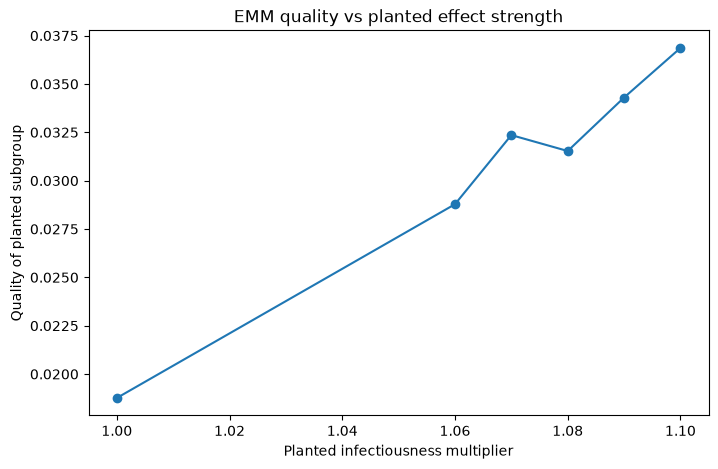

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    effect_strength_df["multiplier"],
    effect_strength_df["target_quality"],
    marker="o",
)

plt.xlabel("Planted infectiousness multiplier")
plt.ylabel("Quality of planted subgroup")
plt.title(
    "EMM quality vs planted effect strength"
)

plt.show()

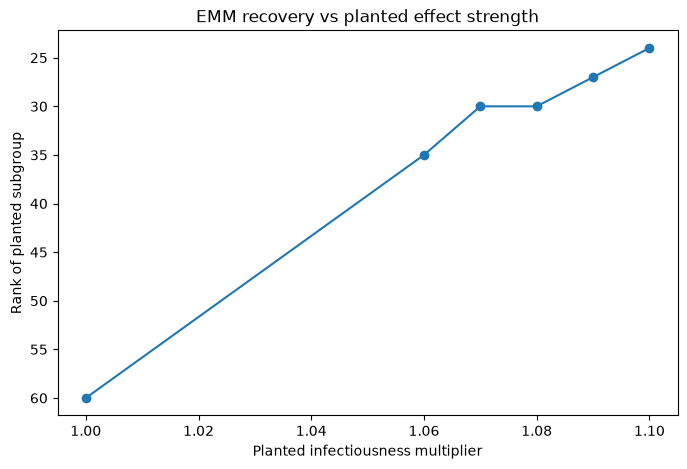

In [47]:
plt.figure(figsize=(8, 5))

plt.plot(
    effect_strength_df["multiplier"],
    effect_strength_df["target_rank"],
    marker="o",
)

plt.xlabel("Planted infectiousness multiplier")
plt.ylabel("Rank of planted subgroup")
plt.title(
    "EMM recovery vs planted effect strength"
)

plt.gca().invert_yaxis()

plt.show()

In [48]:
EFFECT_STRENGTHS = [
    1.00,
    1.04,
    1.05,
    1.06,
    1.07,
    1.08,
    1.10,
]

N_BATCHES = 10
RUNS_PER_BATCH = 100

PLANTED_DESCRIPTION = "smoking == 1 AND age >= 60"

In [49]:
N_BATCHES = 10

In [50]:
def run_ensemble_from_design(
    params,
    seed_sets,
    run_rng_seeds,
):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            edge_multipliers=edge_multipliers,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]

In [51]:
robustness_rows = []

degree = graph.degree()

# One master seed makes the complete experiment reproducible.
master_seed_sequence = np.random.SeedSequence(20261012)

batch_sequences = master_seed_sequence.spawn(
    N_BATCHES
)

for batch_idx, batch_sequence in enumerate(
    batch_sequences
):
    print(
        f"\nBatch {batch_idx + 1}/{N_BATCHES}"
    )

    # Separate random streams for:
    # 1. choosing initial infected nodes
    # 2. epidemic simulation randomness
    seed_sequence, epidemic_sequence = (
        batch_sequence.spawn(2)
    )

    seed_rng = np.random.default_rng(
        seed_sequence
    )

    epidemic_rng = np.random.default_rng(
        epidemic_sequence
    )

    # New epidemic starting nodes for this batch
    seed_sets = [
        np.sort(
            seed_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(RUNS_PER_BATCH)
    ]

    # New simulation RNG seeds for this batch
    run_rng_seeds = epidemic_rng.integers(
        0,
        2**32 - 1,
        size=RUNS_PER_BATCH,
        dtype=np.uint32,
    )

    # IMPORTANT:
    # seed_sets and run_rng_seeds stay identical
    # across all multipliers inside this batch.

    for multiplier in EFFECT_STRENGTHS:

        print(
            f"  multiplier = {multiplier:.2f}"
        )

        current_params = base_params.scaled(
            planted_mask,
            infectiousness=multiplier,
        )

        current_runs = run_ensemble_from_design(
            current_params,
            seed_sets,
            run_rng_seeds,
        )

        final_sizes = np.array(
            [
                run.final_size
                for run in current_runs
            ]
        )

        (
            infection_count,
            mean_secondary,
        ) = per_node_spreading_metrics(
            current_runs
        )

        baseline = fit_degree_baseline(
            degree,
            mean_secondary,
        )

        current_df = people.copy()

        current_df["degree"] = degree

        current_df["infection_count"] = (
            infection_count
        )

        current_df["mean_secondary"] = (
            mean_secondary
        )

        current_df["expected_spread"] = (
            baseline.expected
        )

        current_df["residual"] = (
            baseline.residuals
        )

        results = search_subgroups(
            current_df,
            target_column="residual",
            categorical_columns=CATEGORICAL_COLUMNS,
            age_column="age",
            age_thresholds=range(20, 81, 5),
            min_size=200,
            max_depth=2,
            direction="high",
        )

        # Keep the same pair-only ranking definition
        # used in our previous experiment.
        pairs = (
            results[
                results["depth"] == 2
            ]
            .reset_index(drop=True)
        )

        target_match = pairs[
            pairs["description"]
            == PLANTED_DESCRIPTION
        ]

        if len(target_match) > 0:

            target_rank = int(
                target_match.index[0] + 1
            )

            target_quality = float(
                target_match.iloc[0][
                    "quality"
                ]
            )

        else:

            target_rank = np.nan
            target_quality = np.nan

        top_result = pairs.iloc[0]

        planted_mean_residual = (
            np.nanmean(
                baseline.residuals[
                    planted_mask
                ]
            )
        )

        nonplanted_mean_residual = (
            np.nanmean(
                baseline.residuals[
                    ~planted_mask
                ]
            )
        )

        robustness_rows.append(
            {
                "batch": batch_idx + 1,
                "multiplier": multiplier,

                "mean_fraction_infected":
                    final_sizes.mean()
                    / N_NODES,

                "residual_difference":
                    planted_mean_residual
                    - nonplanted_mean_residual,

                "target_rank":
                    target_rank,

                "target_quality":
                    target_quality,

                "top_description":
                    top_result[
                        "description"
                    ],

                "top_quality":
                    float(
                        top_result[
                            "quality"
                        ]
                    ),

                "exact_recovery":
                    target_rank == 1,

                "top5_recovery":
                    target_rank <= 5,
            }
        )

robustness_df = pd.DataFrame(
    robustness_rows
)

robustness_df.head(20)


Batch 1/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 2/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 3/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 4/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 5/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 6/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 7/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1

,batch,multiplier,mean_fraction_infected,residual_difference,target_rank,target_quality,top_description,top_quality,exact_recovery,top5_recovery
0,1,1.00,0.623213,0.060302,52,0.020548,obesity == 0 AND age >= 25,0.079345,False,False
1,1,1.04,0.624839,0.081320,37,0.027710,obesity == 0 AND age >= 30,0.080963,False,False
2,1,1.05,0.624224,0.083750,33,0.028538,obesity == 0 AND age >= 25,0.076262,False,False
3,1,1.06,0.625396,0.087048,33,0.029662,obesity == 0 AND age >= 25,0.079496,False,False
4,1,1.07,0.625830,0.088935,34,0.030305,obesity == 0 AND age >= 30,0.082695,False,False
5,1,1.08,0.625981,0.094971,29,0.032362,obesity == 0 AND age >= 25,0.082479,False,False
6,1,1.10,0.629189,0.104268,23,0.035530,obesity == 0 AND age >= 25,0.079972,False,False
7,2,1.00,0.624141,0.056858,55,0.019374,obesity == 0 AND age >= 30,0.073097,False,False
8,2,1.04,0.624745,0.086044,35,0.029320,obesity == 0 AND age >= 30,0.080359,False,False
9,2,1.05,0.625195,0.082876,34,0.028240,obesity == 0 AND age >= 30,0.077480,False,False


In [52]:
robustness_summary = (
    robustness_df
    .groupby("multiplier")
    .agg(
        n_batches=(
            "batch",
            "count",
        ),

        mean_fraction_infected=(
            "mean_fraction_infected",
            "mean",
        ),

        mean_residual_difference=(
            "residual_difference",
            "mean",
        ),

        mean_target_rank=(
            "target_rank",
            "mean",
        ),

        median_target_rank=(
            "target_rank",
            "median",
        ),

        best_rank=(
            "target_rank",
            "min",
        ),

        worst_rank=(
            "target_rank",
            "max",
        ),

        mean_target_quality=(
            "target_quality",
            "mean",
        ),

        sd_target_quality=(
            "target_quality",
            "std",
        ),

        exact_recovery_rate=(
            "exact_recovery",
            "mean",
        ),

        top5_recovery_rate=(
            "top5_recovery",
            "mean",
        ),
    )
    .reset_index()
)

robustness_summary[
    "exact_recovery_rate_pct"
] = (
    100
    * robustness_summary[
        "exact_recovery_rate"
    ]
)

robustness_summary[
    "top5_recovery_rate_pct"
] = (
    100
    * robustness_summary[
        "top5_recovery_rate"
    ]
)

robustness_summary

,multiplier,n_batches,mean_fraction_infected,mean_residual_difference,mean_target_rank,median_target_rank,best_rank,worst_rank,mean_target_quality,sd_target_quality,exact_recovery_rate,top5_recovery_rate,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,10,0.623203,0.056654,55.9,57.0,47,63,0.019305,0.001561,0.0,0.0,0.0,0.0
1,1.04,10,0.624693,0.079681,37.5,37.0,35,42,0.027151,0.001790,0.0,0.0,0.0,0.0
2,1.05,10,0.624922,0.083445,35.2,35.5,33,37,0.028434,0.000561,0.0,0.0,0.0,0.0
3,1.06,10,0.625651,0.088112,32.7,33.5,25,39,0.030024,0.001442,0.0,0.0,0.0,0.0
4,1.07,10,0.626329,0.090330,31.9,32.0,29,36,0.030780,0.001400,0.0,0.0,0.0,0.0
5,1.08,10,0.626993,0.095239,29.1,28.5,24,37,0.032453,0.001983,0.0,0.0,0.0,0.0
6,1.10,10,0.627563,0.107146,23.6,24.0,20,28,0.036510,0.001676,0.0,0.0,0.0,0.0


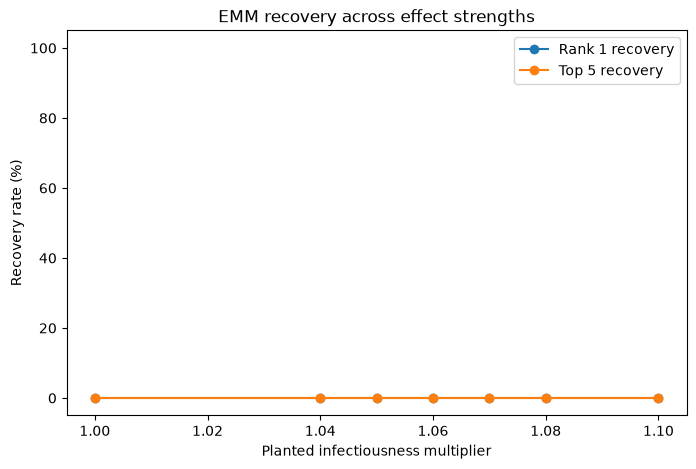

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(
    robustness_summary["multiplier"],
    robustness_summary[
        "exact_recovery_rate_pct"
    ],
    marker="o",
    label="Rank 1 recovery",
)

plt.plot(
    robustness_summary["multiplier"],
    robustness_summary[
        "top5_recovery_rate_pct"
    ],
    marker="o",
    label="Top 5 recovery",
)

plt.xlabel(
    "Planted infectiousness multiplier"
)

plt.ylabel(
    "Recovery rate (%)"
)

plt.title(
    "EMM recovery across effect strengths"
)

plt.ylim(-5, 105)

plt.legend()

plt.show()

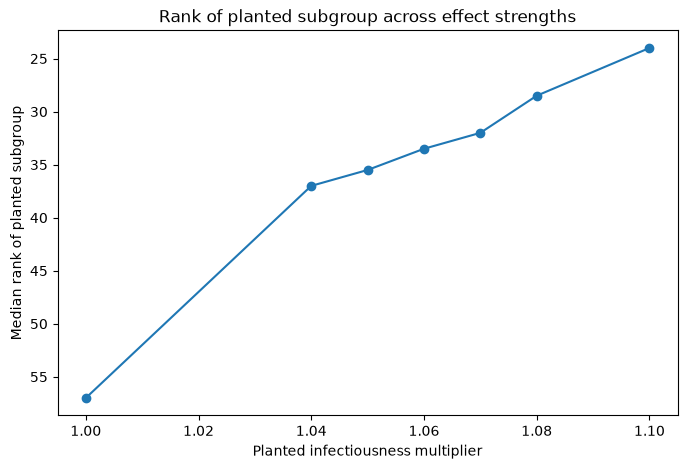

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(
    robustness_summary["multiplier"],
    robustness_summary[
        "median_target_rank"
    ],
    marker="o",
)

plt.xlabel(
    "Planted infectiousness multiplier"
)

plt.ylabel(
    "Median rank of planted subgroup"
)

plt.title(
    "Rank of planted subgroup across effect strengths"
)

plt.gca().invert_yaxis()

plt.show()

In [55]:
control_model_b = model_b_observations(
    graph,
    control_runs,
    susceptibility=infection_rate,
    edge_multipliers=edge_multipliers,
)

planted_model_b = model_b_observations(
    graph,
    planted_runs,
    susceptibility=infection_rate,
    edge_multipliers=edge_multipliers,
)

print(
    "Control Model B observations:",
    len(control_model_b.node_index),
)

print(
    "Planted Model B observations:",
    len(planted_model_b.node_index),
)

Control Model B observations: 616609
Planted Model B observations: 654794


In [56]:
def model_b_to_dataframe(observations):
    df = pd.DataFrame(
        {
            "run": observations.run_index,
            "node_id": observations.node_index,
            "offspring": observations.offspring,
            "opportunity": observations.opportunity,
            "descendants": observations.descendants,
        }
    )

    descriptor_columns = [
        "age",
        "sex",
        "occupation",
        "smoking",
        "alcohol",
        "obesity",
    ]

    node_index = observations.node_index

    for column in descriptor_columns:
        df[column] = people.iloc[node_index][column].to_numpy()

    # Ground truth is added only for evaluation/sanity checks.
    # It must not be used as an EMM descriptor.
    df["is_planted"] = planted_mask[node_index]

    df["offspring_per_opportunity"] = np.divide(
        df["offspring"].to_numpy(dtype=np.float64),
        df["opportunity"].to_numpy(dtype=np.float64),
        out=np.full(len(df), np.nan, dtype=np.float64),
        where=df["opportunity"].to_numpy() > 0,
    )

    return df


control_model_b_df = model_b_to_dataframe(
    control_model_b
)

planted_model_b_df = model_b_to_dataframe(
    planted_model_b
)

planted_model_b_df.head()


,run,node_id,offspring,opportunity,descendants,age,sex,occupation,smoking,alcohol,obesity,is_planted,offspring_per_opportunity
0,0,0,1,23,2,62,Female,Student,0,0,0,False,0.043478
1,0,2,3,43,25,40,Male,Agriculture,1,1,1,False,0.069767
2,0,3,1,13,3,70,Male,Office-based,1,1,0,True,0.076923
3,0,4,4,93,25,54,Male,Healthcare,0,0,0,False,0.043011
4,0,5,2,40,10,13,Male,Student,0,1,0,False,0.050000


In [57]:
# Sanity checks for the extracted Model B quantities.

assert np.all(
    control_model_b.offspring
    <= control_model_b.opportunity
)
assert np.all(
    planted_model_b.offspring
    <= planted_model_b.opportunity
)

assert np.all(
    control_model_b.descendants
    >= control_model_b.offspring
)
assert np.all(
    planted_model_b.descendants
    >= planted_model_b.offspring
)

print(
    "Control zero-opportunity observations:",
    (control_model_b_df["opportunity"] == 0).sum(),
)
print(
    "Planted zero-opportunity observations:",
    (planted_model_b_df["opportunity"] == 0).sum(),
)

planted_model_b_df[
    ["offspring", "opportunity", "descendants"]
].describe()


Control zero-opportunity observations: 703
Planted zero-opportunity observations: 1194


,offspring,opportunity,descendants
count,654794.000000,654794.000000,654794.000000
mean,0.987683,22.281012,8.013116
std,1.224898,18.921960,29.094396
min,0.000000,0.000000,0.000000
25%,0.000000,10.000000,0.000000
50%,1.000000,16.000000,1.000000
75%,2.000000,29.000000,5.000000
max,14.000000,270.000000,1523.000000


In [58]:
def pooled_model_b_rates(df):
    summary = (
        df.groupby("is_planted")
        .agg(
            observations=("node_id", "size"),
            total_offspring=("offspring", "sum"),
            total_opportunity=("opportunity", "sum"),
            mean_descendants=("descendants", "mean"),
        )
    )

    summary["offspring_per_opportunity"] = (
        summary["total_offspring"]
        / summary["total_opportunity"]
    )

    return summary


print("Control")
display(
    pooled_model_b_rates(
        control_model_b_df
    )
)

print("Planted")
display(
    pooled_model_b_rates(
        planted_model_b_df
    )
)


Control


,observations,total_offspring,total_opportunity,mean_descendants,offspring_per_opportunity
is_planted,,,,,
False,559454,568202,13492206,8.678957,0.042113
True,57155,40695,883800,4.746094,0.046045


Planted


,observations,total_offspring,total_opportunity,mean_descendants,offspring_per_opportunity
is_planted,,,,,
False,589041,572839,13663543,8.009164,0.041925
True,65753,73890,925930,8.048515,0.079801


In [59]:
import statsmodels.api as sm

In [60]:
model_b_fit_df = planted_model_b_df[
    planted_model_b_df["opportunity"] > 0
].copy()

model_b_fit_df["log_opportunity"] = np.log(
    model_b_fit_df["opportunity"]
)

model_b_fit_df["group"] = (
    model_b_fit_df["is_planted"]
    .astype(int)
)

In [61]:
X = sm.add_constant(
    model_b_fit_df[["group"]]
)

model_b_nb = sm.GLM(
    model_b_fit_df["offspring"],
    X,
    family=sm.families.NegativeBinomial(),
    offset=model_b_fit_df["log_opportunity"],
)

model_b_result = model_b_nb.fit()

print(model_b_result.summary())

/tmp/ipykernel_10696/3285573212.py:8: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


                 Generalized Linear Model Regression Results                  
Dep. Variable:              offspring   No. Observations:               653600
Model:                            GLM   Df Residuals:                   653598
Model Family:        NegativeBinomial   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -8.2400e+05
Date:                Thu, 22 Oct 2026   Deviance:                   4.0109e+05
Time:                        01:06:30   Pearson chi2:                 3.66e+05
No. Iterations:                     5   Pseudo R-squ. (CS):            0.01790
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.1533      0.002  -1594.130      0.0

In [62]:
beta_group = model_b_result.params["group"]

rate_ratio = np.exp(beta_group)

print(
    "Group coefficient:",
    beta_group
)

print(
    "Transmission rate ratio:",
    rate_ratio
)

Group coefficient: 0.6649063491184731
Transmission rate ratio: 1.944308426612186


In [63]:
control_fit_df = control_model_b_df[
    control_model_b_df["opportunity"] > 0
].copy()

control_fit_df["log_opportunity"] = np.log(
    control_fit_df["opportunity"]
)

control_fit_df["group"] = (
    control_fit_df["is_planted"]
    .astype(int)
)

X_control = sm.add_constant(
    control_fit_df[["group"]]
)

control_nb = sm.GLM(
    control_fit_df["offspring"],
    X_control,
    family=sm.families.NegativeBinomial(),
    offset=control_fit_df["log_opportunity"],
)

control_result = control_nb.fit()

print(
    "CONTROL rate ratio:",
    np.exp(
        control_result.params["group"]
    )
)

/tmp/ipykernel_10696/386345837.py:21: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


CONTROL rate ratio: 1.1053913230662882


In [64]:
X = sm.add_constant(
    model_b_fit_df[["group"]]
)

model_b_nb = sm.NegativeBinomial(
    model_b_fit_df["offspring"],
    X,
    exposure=model_b_fit_df["opportunity"],
)

model_b_result = model_b_nb.fit()

print(model_b_result.summary())

Optimization terminated successfully.
         Current function value: 1.166499
         Iterations: 26
         Function evaluations: 28
         Gradient evaluations: 28
                     NegativeBinomial Regression Results                      
Dep. Variable:              offspring   No. Observations:               653600
Model:               NegativeBinomial   Df Residuals:                   653598
Method:                           MLE   Df Model:                            1
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                 0.01486
Time:                        01:07:19   Log-Likelihood:            -7.6242e+05
converged:                       True   LL-Null:                   -7.7393e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.1719      0.001  -240

In [65]:
beta_group = model_b_result.params["group"]
rate_ratio = np.exp(beta_group)

print("Group coefficient:", beta_group)
print("Transmission rate ratio:", rate_ratio)
print("Estimated alpha:", model_b_result.params["alpha"])

Group coefficient: 0.6436418056910862
Transmission rate ratio: 1.9034000857195832
Estimated alpha: 7.50705184536322e-07


In [66]:
X_control = sm.add_constant(
    control_fit_df[["group"]]
)

control_nb = sm.NegativeBinomial(
    control_fit_df["offspring"],
    X_control,
    exposure=control_fit_df["opportunity"],
)

control_result = control_nb.fit()

print(
    "CONTROL rate ratio:",
    np.exp(
        control_result.params["group"]
    )
)

print(
    "CONTROL alpha:",
    control_result.params["alpha"]
)

Optimization terminated successfully.
         Current function value: 1.167253
         Iterations: 23
         Function evaluations: 25
         Gradient evaluations: 25
CONTROL rate ratio: 1.0934017313791802
CONTROL alpha: 3.413299846252316e-07


In [67]:
X = sm.add_constant(
    model_b_fit_df[["group"]]
)

poisson_model = sm.GLM(
    model_b_fit_df["offspring"],
    X,
    family=sm.families.Poisson(),
    offset=model_b_fit_df["log_opportunity"],
)

poisson_result = poisson_model.fit()

print(poisson_result.summary())

print(
    "POISSON planted rate ratio:",
    np.exp(poisson_result.params["group"])
)

print(
    "AIC:",
    poisson_result.aic
)

                 Generalized Linear Model Regression Results                  
Dep. Variable:              offspring   No. Observations:               653600
Model:                            GLM   Df Residuals:                   653598
Model Family:                 Poisson   Df Model:                            1
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -7.6242e+05
Date:                Thu, 22 Oct 2026   Deviance:                   6.6053e+05
Time:                        01:07:29   Pearson chi2:                 6.52e+05
No. Iterations:                     5   Pseudo R-squ. (CS):            0.03459
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.1719      0.001  -2400.675      0.0

In [68]:
X_control = sm.add_constant(
    control_fit_df[["group"]]
)

control_poisson = sm.GLM(
    control_fit_df["offspring"],
    X_control,
    family=sm.families.Poisson(),
    offset=control_fit_df["log_opportunity"],
)

control_poisson_result = (
    control_poisson.fit()
)

print(
    "POISSON control rate ratio:",
    np.exp(
        control_poisson_result.params["group"]
    )
)

print(
    "AIC:",
    control_poisson_result.aic
)

POISSON control rate ratio: 1.0933702705022528
AIC: 1437840.4759275704


In [69]:
pearson_dispersion = (
    np.sum(
        poisson_result.resid_pearson ** 2
    )
    / poisson_result.df_resid
)

print(
    "Poisson Pearson dispersion:",
    pearson_dispersion
)

Poisson Pearson dispersion: 0.9979763499393592


In [70]:
MODEL_B_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]

model_b_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=200,
    max_depth=2,
    direction="high",
)

model_b_results.head(20)

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,1161,0.1161,65753,589041,raw,73890.0,925930.0,0.079801,572839.0,13663543.0,0.041925,1.903436,0.643661,0.219317
1,1,age >= 60,1960,0.1960,107838,546956,raw,101983.0,1538976.0,0.066267,544746.0,13050497.0,0.041741,1.587556,0.462195,0.204623
2,2,obesity == 0 AND age >= 60,1827,0.1827,100190,554604,raw,94833.0,1431687.0,0.066239,551896.0,13157786.0,0.041944,1.579199,0.456918,0.195302
3,2,smoking == 1 AND age >= 65,772,0.0772,38934,615860,raw,35545.0,423314.0,0.083968,611184.0,14166159.0,0.043144,1.946238,0.665898,0.185019
4,2,smoking == 1 AND age >= 55,1575,0.1575,94572,560222,raw,98979.0,1498842.0,0.066037,547750.0,13090631.0,0.041843,1.578212,0.456293,0.181086
5,1,age >= 65,1277,0.1277,62225,592569,raw,47688.0,674961.0,0.070653,599041.0,13914512.0,0.043052,1.641126,0.495382,0.177026
6,1,age >= 55,2642,0.2642,153420,501374,raw,141170.0,2437188.0,0.057923,505559.0,12152285.0,0.041602,1.392321,0.330972,0.170121
7,2,obesity == 0 AND age >= 65,1189,0.1189,57665,597129,raw,44265.0,627599.0,0.070531,602464.0,13961874.0,0.043151,1.634522,0.491351,0.169427
8,2,obesity == 0 AND age >= 55,2464,0.2464,142561,512233,raw,131225.0,2262960.0,0.057988,515504.0,12326513.0,0.041821,1.386589,0.326847,0.162243
9,2,alcohol == 0 AND age >= 60,1381,0.1381,73999,580795,raw,69492.0,1061522.0,0.065464,577237.0,13527951.0,0.042670,1.534206,0.428013,0.159057


In [71]:
PLANTED_DESCRIPTION = (
    "smoking == 1 AND age >= 60"
)

target = model_b_results[
    model_b_results["description"]
    == PLANTED_DESCRIPTION
]

target

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,1161,0.1161,65753,589041,raw,73890.0,925930.0,0.079801,572839.0,13663543.0,0.041925,1.903436,0.643661,0.219317


In [72]:
target_rank = (
    target.index[0] + 1
)

print(
    "Model B planted subgroup rank:",
    target_rank,
)

print(
    "Estimated rate ratio:",
    target.iloc[0]["rate_ratio"],
)

print(
    "Log rate ratio:",
    target.iloc[0]["log_rate_ratio"],
)

print(
    "Quality:",
    target.iloc[0]["quality"],
)

Model B planted subgroup rank: 1
Estimated rate ratio: 1.903435921886163
Log rate ratio: 0.6436606329620845
Quality: 0.2193173844234881


In [73]:
control_model_b_results = search_model_b_subgroups(
    people,
    control_model_b,
    categorical_columns=MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
)

control_model_b_results.head(20)

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,1,age >= 25,6695,0.6695,404946,211663,raw,390376.0,8851774.0,0.044101,218521.0,5524232.0,0.039557,1.114889,0.108755,0.088986
1,1,age >= 30,6000,0.6000,362982,253627,raw,350176.0,7878472.0,0.044447,258721.0,6497534.0,0.039818,1.116249,0.109974,0.085186
2,1,age >= 20,7341,0.7341,440739,175870,raw,421532.0,9657149.0,0.043650,187365.0,4718857.0,0.039706,1.099335,0.094705,0.081143
3,2,obesity == 0 AND age >= 25,6230,0.6230,374983,241626,raw,361818.0,8203869.0,0.044103,247079.0,6172137.0,0.040031,1.101720,0.096872,0.076462
4,2,obesity == 0 AND age >= 30,5578,0.5578,335860,280749,raw,324389.0,7298144.0,0.044448,284508.0,7077862.0,0.040197,1.105761,0.100534,0.075085
5,1,age >= 35,5308,0.5308,315924,300685,raw,298289.0,6680112.0,0.044653,310608.0,7695894.0,0.040360,1.106369,0.101083,0.073645
6,2,obesity == 0 AND age >= 20,6825,0.6825,407795,208814,raw,390398.0,8942405.0,0.043657,218499.0,5433601.0,0.040213,1.085654,0.082183,0.067894
7,2,obesity == 0 AND age >= 35,4931,0.4931,292131,324478,raw,276299.0,6187330.0,0.044656,332598.0,8188676.0,0.040617,1.099436,0.094798,0.066568
8,1,age >= 40,4591,0.4591,268078,348531,raw,245989.0,5486529.0,0.044835,362908.0,8889477.0,0.040824,1.098241,0.093710,0.063495
9,2,obesity == 0 AND age >= 40,4260,0.4260,247542,369067,raw,227204.0,5068175.0,0.044830,381693.0,9307831.0,0.041008,1.093198,0.089107,0.058159


In [74]:
control_target = control_model_b_results[
    control_model_b_results["description"]
    == PLANTED_DESCRIPTION
]

control_target_rank = (
    control_target.index[0] + 1
)

print(
    "CONTROL Model B planted subgroup rank:",
    control_target_rank,
)

print(
    "CONTROL estimated rate ratio:",
    control_target.iloc[0]["rate_ratio"],
)

print(
    "CONTROL log rate ratio:",
    control_target.iloc[0]["log_rate_ratio"],
)

print(
    "CONTROL quality:",
    control_target.iloc[0]["quality"],
)

CONTROL Model B planted subgroup rank: 55
CONTROL estimated rate ratio: 1.0933702705022483
CONTROL log rate ratio: 0.08926491715323517
CONTROL quality: 0.030415636980520633


In [75]:
current_model_b = (
    model_b_observations(
        graph,
        current_runs,
        susceptibility=infection_rate,
        edge_multipliers=edge_multipliers,
    )
)

results = search_model_b_subgroups(
    people,
    current_model_b,
    categorical_columns=MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
)

In [76]:
EFFECT_STRENGTHS = [
    1.00,
    1.04,
    1.05,
    1.06,
    1.07,
    1.08,
    1.10,
]

N_MODEL_B_BATCHES = 10
RUNS_PER_BATCH = 100

PLANTED_DESCRIPTION = (
    "smoking == 1 AND age >= 60"
)

MODEL_B_CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]

In [77]:
def run_ensemble_from_design(
    params,
    seed_sets,
    run_rng_seeds,
):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            edge_multipliers=
                edge_multipliers,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]

In [78]:
model_b_robustness_rows = []

master_seed_sequence = np.random.SeedSequence(
    20261012
)

batch_sequences = master_seed_sequence.spawn(
    N_MODEL_B_BATCHES
)

for batch_idx, batch_sequence in enumerate(
    batch_sequences
):

    print(
        f"\nBatch "
        f"{batch_idx + 1}/"
        f"{N_MODEL_B_BATCHES}"
    )

    (
        seed_sequence,
        epidemic_sequence,
    ) = batch_sequence.spawn(2)

    seed_rng = np.random.default_rng(
        seed_sequence
    )

    epidemic_rng = np.random.default_rng(
        epidemic_sequence
    )

    # Same initial infections for every
    # multiplier within this batch.
    seed_sets = [
        np.sort(
            seed_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(
            RUNS_PER_BATCH
        )
    ]

    # Same simulation RNG seeds for every
    # multiplier within this batch.
    run_rng_seeds = (
        epidemic_rng.integers(
            0,
            2**32 - 1,
            size=RUNS_PER_BATCH,
            dtype=np.uint32,
        )
    )

    for multiplier in EFFECT_STRENGTHS:

        print(
            f"  multiplier = "
            f"{multiplier:.2f}"
        )

        current_params = (
            base_params.scaled(
                planted_mask,
                infectiousness=multiplier,
            )
        )

        current_runs = (
            run_ensemble_from_design(
                current_params,
                seed_sets,
                run_rng_seeds,
            )
        )

        # Overall epidemic size.
        final_sizes = np.array(
            [
                run.final_size
                for run in current_runs
            ]
        )

        # Extract Model B observations:
        # offspring, raw opportunity,
        # susceptibility-weighted opportunity,
        # descendants, node/run ids.
        current_model_b = (
    model_b_observations(
        graph,
        current_runs,
        susceptibility=infection_rate,
        edge_multipliers=edge_multipliers,
    )
)

        # Run the complete susceptibility-weighted
        # Model B EMM search across depth 1 and 2.
        results = (
            search_model_b_subgroups(
                people,
                current_model_b,
                categorical_columns=(
                    MODEL_B_CATEGORICAL_COLUMNS
                ),
                age_column="age",
                age_thresholds=range(
                    20,
                    81,
                    5,
                ),
                min_size=200,
                max_depth=2,
                direction="high",
                opportunity_type="weighted",
            )
        )

        target_match = results[
            results["description"]
            == PLANTED_DESCRIPTION
        ]

        if len(target_match) > 0:

            target_rank = int(
                target_match.index[0]
                + 1
            )

            target_rate_ratio = float(
                target_match.iloc[0][
                    "rate_ratio"
                ]
            )

            target_log_rate_ratio = float(
                target_match.iloc[0][
                    "log_rate_ratio"
                ]
            )

            target_quality = float(
                target_match.iloc[0][
                    "quality"
                ]
            )

        else:

            target_rank = np.nan
            target_rate_ratio = np.nan
            target_log_rate_ratio = np.nan
            target_quality = np.nan

        top_result = results.iloc[0]

        model_b_robustness_rows.append(
            {
                "batch":
                    batch_idx + 1,

                "multiplier":
                    multiplier,

                "mean_fraction_infected":
                    final_sizes.mean()
                    / N_NODES,

                "target_rank":
                    target_rank,

                "target_rate_ratio":
                    target_rate_ratio,

                "target_log_rate_ratio":
                    target_log_rate_ratio,

                "target_quality":
                    target_quality,

                "top_description":
                    top_result[
                        "description"
                    ],

                "top_rate_ratio":
                    float(
                        top_result[
                            "rate_ratio"
                        ]
                    ),

                "top_quality":
                    float(
                        top_result[
                            "quality"
                        ]
                    ),

                "exact_recovery":
                    target_rank == 1,

                "top5_recovery":
                    target_rank <= 5,
            }
        )


model_b_robustness_df = pd.DataFrame(
    model_b_robustness_rows
)

model_b_robustness_df.head(20)


Batch 1/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 2/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 3/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 4/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 5/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 6/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 7/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1

,batch,multiplier,mean_fraction_infected,target_rank,target_rate_ratio,target_log_rate_ratio,target_quality,top_description,top_rate_ratio,top_quality,exact_recovery,top5_recovery
0,1,1.00,0.623213,35,1.010670,0.010614,0.003616,age >= 20,1.009167,0.007818,False,False
1,1,1.04,0.624839,1,1.048426,0.047290,0.016113,smoking == 1 AND age >= 60,1.048426,0.016113,True,True
2,1,1.05,0.624224,1,1.062037,0.060188,0.020508,smoking == 1 AND age >= 60,1.062037,0.020508,True,True
3,1,1.06,0.625396,1,1.065950,0.063867,0.021762,smoking == 1 AND age >= 60,1.065950,0.021762,True,True
4,1,1.07,0.625830,1,1.077918,0.075031,0.025566,smoking == 1 AND age >= 60,1.077918,0.025566,True,True
5,1,1.08,0.625981,1,1.086440,0.082906,0.028249,smoking == 1 AND age >= 60,1.086440,0.028249,True,True
6,1,1.10,0.629189,1,1.103659,0.098631,0.033607,smoking == 1 AND age >= 60,1.103659,0.033607,True,True
7,2,1.00,0.624141,37,1.006971,0.006947,0.002367,age >= 45,1.007359,0.004610,False,False
8,2,1.04,0.624745,1,1.054806,0.053357,0.018181,smoking == 1 AND age >= 60,1.054806,0.018181,True,True
9,2,1.05,0.625195,1,1.053863,0.052462,0.017876,smoking == 1 AND age >= 60,1.053863,0.017876,True,True


In [79]:
model_b_robustness_summary = (
    model_b_robustness_df
    .groupby("multiplier")
    .agg(
        n_batches=(
            "batch",
            "count",
        ),

        mean_fraction_infected=(
            "mean_fraction_infected",
            "mean",
        ),

        mean_target_rank=(
            "target_rank",
            "mean",
        ),

        median_target_rank=(
            "target_rank",
            "median",
        ),

        best_rank=(
            "target_rank",
            "min",
        ),

        worst_rank=(
            "target_rank",
            "max",
        ),

        mean_rate_ratio=(
            "target_rate_ratio",
            "mean",
        ),

        sd_rate_ratio=(
            "target_rate_ratio",
            "std",
        ),

        mean_log_rate_ratio=(
            "target_log_rate_ratio",
            "mean",
        ),

        mean_quality=(
            "target_quality",
            "mean",
        ),

        sd_quality=(
            "target_quality",
            "std",
        ),

        exact_recovery_rate=(
            "exact_recovery",
            "mean",
        ),

        top5_recovery_rate=(
            "top5_recovery",
            "mean",
        ),
    )
    .reset_index()
)

model_b_robustness_summary[
    "exact_recovery_rate_pct"
] = (
    100
    * model_b_robustness_summary[
        "exact_recovery_rate"
    ]
)

model_b_robustness_summary[
    "top5_recovery_rate_pct"
] = (
    100
    * model_b_robustness_summary[
        "top5_recovery_rate"
    ]
)

model_b_robustness_summary

,multiplier,n_batches,mean_fraction_infected,mean_target_rank,median_target_rank,best_rank,worst_rank,mean_rate_ratio,sd_rate_ratio,mean_log_rate_ratio,mean_quality,sd_quality,exact_recovery_rate,top5_recovery_rate,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,10,0.623203,105.6,36.0,1,328,1.006121,0.006509,0.006084,0.002073,0.002204,0.1,0.1,10.0,10.0
1,1.04,10,0.624693,1.1,1.0,1,2,1.047782,0.006325,0.046659,0.015898,0.002059,0.9,1.0,90.0,100.0
2,1.05,10,0.624922,1.2,1.0,1,2,1.053752,0.003271,0.052353,0.017838,0.001055,0.8,1.0,80.0,100.0
3,1.06,10,0.625651,1.0,1.0,1,1,1.065642,0.007692,0.063554,0.021655,0.002462,1.0,1.0,100.0,100.0
4,1.07,10,0.626329,1.0,1.0,1,1,1.073600,0.006198,0.071002,0.024193,0.001972,1.0,1.0,100.0,100.0
5,1.08,10,0.626993,1.0,1.0,1,1,1.083462,0.007531,0.080140,0.027306,0.002364,1.0,1.0,100.0,100.0
6,1.10,10,0.627563,1.0,1.0,1,1,1.102974,0.007055,0.097992,0.033389,0.002177,1.0,1.0,100.0,100.0


In [80]:
model_b_robustness_summary[
    [
        "multiplier",
        "mean_rate_ratio",
        "sd_rate_ratio",
    ]
]

,multiplier,mean_rate_ratio,sd_rate_ratio
0,1.00,1.006121,0.006509
1,1.04,1.047782,0.006325
2,1.05,1.053752,0.003271
3,1.06,1.065642,0.007692
4,1.07,1.073600,0.006198
5,1.08,1.083462,0.007531
6,1.10,1.102974,0.007055


In [81]:
model_b_robustness_summary[
    [
        "multiplier",
        "median_target_rank",
        "worst_rank",
        "exact_recovery_rate_pct",
        "top5_recovery_rate_pct",
    ]
]

,multiplier,median_target_rank,worst_rank,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,36.0,328,10.0,10.0
1,1.04,1.0,2,90.0,100.0
2,1.05,1.0,2,80.0,100.0
3,1.06,1.0,1,100.0,100.0
4,1.07,1.0,1,100.0,100.0
5,1.08,1.0,1,100.0,100.0
6,1.10,1.0,1,100.0,100.0


In [82]:
comparison_df = (
    robustness_summary[
        [
            "multiplier",
            "median_target_rank",
            "exact_recovery_rate_pct",
            "top5_recovery_rate_pct",
        ]
    ]
    .rename(
        columns={
            "median_target_rank":
                "baseline_median_rank",

            "exact_recovery_rate_pct":
                "baseline_exact_pct",

            "top5_recovery_rate_pct":
                "baseline_top5_pct",
        }
    )
    .merge(
        model_b_robustness_summary[
            [
                "multiplier",
                "median_target_rank",
                "exact_recovery_rate_pct",
                "top5_recovery_rate_pct",
                "mean_rate_ratio",
            ]
        ].rename(
            columns={
                "median_target_rank":
                    "model_b_median_rank",

                "exact_recovery_rate_pct":
                    "model_b_exact_pct",

                "top5_recovery_rate_pct":
                    "model_b_top5_pct",
            }
        ),
        on="multiplier",
    )
)

comparison_df

,multiplier,baseline_median_rank,baseline_exact_pct,baseline_top5_pct,model_b_median_rank,model_b_exact_pct,model_b_top5_pct,mean_rate_ratio
0,1.00,57.0,0.0,0.0,36.0,10.0,10.0,1.006121
1,1.04,37.0,0.0,0.0,1.0,90.0,100.0,1.047782
2,1.05,35.5,0.0,0.0,1.0,80.0,100.0,1.053752
3,1.06,33.5,0.0,0.0,1.0,100.0,100.0,1.065642
4,1.07,32.0,0.0,0.0,1.0,100.0,100.0,1.073600
5,1.08,28.5,0.0,0.0,1.0,100.0,100.0,1.083462
6,1.10,24.0,0.0,0.0,1.0,100.0,100.0,1.102974


In [83]:
control_model_b = model_b_observations(
    graph,
    control_runs,
    susceptibility=infection_rate,
    edge_multipliers=edge_multipliers,
)

planted_model_b = model_b_observations(
    graph,
    planted_runs,
    susceptibility=infection_rate,
    edge_multipliers=edge_multipliers,
)

In [84]:
print(
    planted_model_b.weighted_opportunity[:10]
)

print(
    planted_model_b.opportunity[:10]
)

[ 9.3398 17.4365  6.6749 34.5832 14.3403  1.5188  4.1527  8.6625  1.0932
  3.5082]
[23 43 13 93 40  5 13 25  4 10]


In [85]:
raw_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
    opportunity_type="raw",
)

weighted_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
    opportunity_type="weighted",
)

In [86]:
weighted_results = search_model_b_subgroups(
    people,
    planted_model_b,
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
    opportunity_type="weighted",
)

weighted_target = weighted_results[
    weighted_results["description"]
    == PLANTED_DESCRIPTION
]

print(
    "WEIGHTED rank:",
    weighted_target.index[0] + 1,
)

print(
    "WEIGHTED RR:",
    weighted_target.iloc[0]["rate_ratio"],
)

print(
    "WEIGHTED log RR:",
    weighted_target.iloc[0]["log_rate_ratio"],
)

print(
    "WEIGHTED quality:",
    weighted_target.iloc[0]["quality"],
)

WEIGHTED rank: 1
WEIGHTED RR: 1.7527348022477351
WEIGHTED log RR: 0.5611773122630324
WEIGHTED quality: 0.19121247132505803


In [87]:
weighted_results.head(20)

,depth,description,size,support,observations,rest_observations,opportunity_type,group_offspring,group_opportunity,group_rate,rest_offspring,rest_opportunity,rest_rate,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,1161,0.1161,65753,589041,weighted,73890.0,3.603806e+05,0.205033,572839.0,4.896937e+06,0.116979,1.752735,0.561177,0.191212
1,1,age >= 60,1960,0.1960,107838,546956,weighted,101983.0,5.996341e+05,0.170075,544746.0,4.657684e+06,0.116956,1.454177,0.374440,0.165772
2,2,obesity == 0 AND age >= 60,1827,0.1827,100190,554604,weighted,94833.0,5.579806e+05,0.169958,551896.0,4.699337e+06,0.117441,1.447171,0.369610,0.157984
3,2,smoking == 1 AND age >= 55,1575,0.1575,94572,560222,weighted,98979.0,5.742407e+05,0.172365,547750.0,4.683077e+06,0.116964,1.473663,0.387751,0.153884
4,2,smoking == 1 AND age >= 65,772,0.0772,38934,615860,weighted,35545.0,1.723960e+05,0.206182,611184.0,5.084922e+06,0.120195,1.715393,0.539642,0.149939
5,2,smoking == 1 AND age >= 50,1960,0.1960,121876,532918,weighted,123280.0,7.817657e+05,0.157694,523449.0,4.475552e+06,0.116957,1.348305,0.298849,0.132306
6,1,age >= 55,2642,0.2642,153420,501374,weighted,141170.0,9.344110e+05,0.151079,505559.0,4.322907e+06,0.116949,1.291839,0.256067,0.131619
7,1,age >= 65,1277,0.1277,62225,592569,weighted,47688.0,2.756039e+05,0.173031,599041.0,4.981714e+06,0.120248,1.438951,0.363914,0.130045
8,2,alcohol == 0 AND age >= 60,1381,0.1381,73999,580795,weighted,69492.0,4.130632e+05,0.168236,577237.0,4.844254e+06,0.119159,1.411858,0.344907,0.128174
9,2,obesity == 0 AND age >= 55,2464,0.2464,142561,512233,weighted,131225.0,8.680201e+05,0.151177,515504.0,4.389298e+06,0.117446,1.287211,0.252478,0.125327


In [88]:
weighted_control_results = (
    search_model_b_subgroups(
        people,
        control_model_b,
        categorical_columns=
            MODEL_B_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type="weighted",
    )
)

weighted_control_target = (
    weighted_control_results[
        weighted_control_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL weighted rank:",
    weighted_control_target.index[0] + 1,
)

print(
    "CONTROL weighted RR:",
    weighted_control_target.iloc[0][
        "rate_ratio"
    ],
)

print(
    "CONTROL weighted quality:",
    weighted_control_target.iloc[0][
        "quality"
    ],
)

CONTROL weighted rank: 207
CONTROL weighted RR: 1.0005892154321845
CONTROL weighted quality: 0.00020070690212135845


In [89]:
weighted_model_b_robustness_rows = []

master_seed_sequence = np.random.SeedSequence(
    20261012
)

batch_sequences = master_seed_sequence.spawn(
    N_MODEL_B_BATCHES
)

for batch_idx, batch_sequence in enumerate(
    batch_sequences
):

    print(
        f"\nBatch "
        f"{batch_idx + 1}/"
        f"{N_MODEL_B_BATCHES}"
    )

    (
        seed_sequence,
        epidemic_sequence,
    ) = batch_sequence.spawn(2)

    seed_rng = np.random.default_rng(
        seed_sequence
    )

    epidemic_rng = np.random.default_rng(
        epidemic_sequence
    )

    # Same initial seed sets for all
    # multipliers within this batch.
    seed_sets = [
        np.sort(
            seed_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(
            RUNS_PER_BATCH
        )
    ]

    # Same epidemic RNG seeds for all
    # multipliers within this batch.
    run_rng_seeds = (
        epidemic_rng.integers(
            0,
            2**32 - 1,
            size=RUNS_PER_BATCH,
            dtype=np.uint32,
        )
    )

    for multiplier in EFFECT_STRENGTHS:

        print(
            f"  multiplier = "
            f"{multiplier:.2f}"
        )

        current_params = (
            base_params.scaled(
                planted_mask,
                infectiousness=multiplier,
            )
        )

        current_runs = (
            run_ensemble_from_design(
                current_params,
                seed_sets,
                run_rng_seeds,
            )
        )

        final_sizes = np.array(
            [
                run.final_size
                for run in current_runs
            ]
        )

        # Model B observations with both
        # raw and susceptibility-weighted
        # opportunity.
        current_model_b = (
    model_b_observations(
        graph,
        current_runs,
        susceptibility=infection_rate,
        edge_multipliers=edge_multipliers,
    )
)

        # Weighted Model B EMM.
        results = (
            search_model_b_subgroups(
                people,
                current_model_b,
                categorical_columns=(
                    MODEL_B_CATEGORICAL_COLUMNS
                ),
                age_column="age",
                age_thresholds=range(
                    20,
                    81,
                    5,
                ),
                min_size=200,
                max_depth=2,
                direction="high",
                opportunity_type="weighted",
            )
        )

        target_match = results[
            results["description"]
            == PLANTED_DESCRIPTION
        ]

        if len(target_match) > 0:

            target_rank = int(
                target_match.index[0]
                + 1
            )

            target_rate_ratio = float(
                target_match.iloc[0][
                    "rate_ratio"
                ]
            )

            target_log_rate_ratio = float(
                target_match.iloc[0][
                    "log_rate_ratio"
                ]
            )

            target_quality = float(
                target_match.iloc[0][
                    "quality"
                ]
            )

        else:

            target_rank = np.nan
            target_rate_ratio = np.nan
            target_log_rate_ratio = np.nan
            target_quality = np.nan

        top_result = results.iloc[0]

        weighted_model_b_robustness_rows.append(
            {
                "batch":
                    batch_idx + 1,

                "multiplier":
                    multiplier,

                "mean_fraction_infected":
                    final_sizes.mean()
                    / N_NODES,

                "target_rank":
                    target_rank,

                "target_rate_ratio":
                    target_rate_ratio,

                "target_log_rate_ratio":
                    target_log_rate_ratio,

                "target_quality":
                    target_quality,

                "top_description":
                    top_result[
                        "description"
                    ],

                "top_rate_ratio":
                    float(
                        top_result[
                            "rate_ratio"
                        ]
                    ),

                "top_quality":
                    float(
                        top_result[
                            "quality"
                        ]
                    ),

                "exact_recovery":
                    target_rank == 1,

                "top5_recovery":
                    target_rank <= 5,
            }
        )


weighted_model_b_robustness_df = pd.DataFrame(
    weighted_model_b_robustness_rows
)

weighted_model_b_robustness_df.head(20)


Batch 1/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 2/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 3/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 4/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 5/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 6/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1.06
  multiplier = 1.07
  multiplier = 1.08
  multiplier = 1.10

Batch 7/10
  multiplier = 1.00
  multiplier = 1.04
  multiplier = 1.05
  multiplier = 1

,batch,multiplier,mean_fraction_infected,target_rank,target_rate_ratio,target_log_rate_ratio,target_quality,top_description,top_rate_ratio,top_quality,exact_recovery,top5_recovery
0,1,1.00,0.623213,35,1.010670,0.010614,0.003616,age >= 20,1.009167,0.007818,False,False
1,1,1.04,0.624839,1,1.048426,0.047290,0.016113,smoking == 1 AND age >= 60,1.048426,0.016113,True,True
2,1,1.05,0.624224,1,1.062037,0.060188,0.020508,smoking == 1 AND age >= 60,1.062037,0.020508,True,True
3,1,1.06,0.625396,1,1.065950,0.063867,0.021762,smoking == 1 AND age >= 60,1.065950,0.021762,True,True
4,1,1.07,0.625830,1,1.077918,0.075031,0.025566,smoking == 1 AND age >= 60,1.077918,0.025566,True,True
5,1,1.08,0.625981,1,1.086440,0.082906,0.028249,smoking == 1 AND age >= 60,1.086440,0.028249,True,True
6,1,1.10,0.629189,1,1.103659,0.098631,0.033607,smoking == 1 AND age >= 60,1.103659,0.033607,True,True
7,2,1.00,0.624141,37,1.006971,0.006947,0.002367,age >= 45,1.007359,0.004610,False,False
8,2,1.04,0.624745,1,1.054806,0.053357,0.018181,smoking == 1 AND age >= 60,1.054806,0.018181,True,True
9,2,1.05,0.625195,1,1.053863,0.052462,0.017876,smoking == 1 AND age >= 60,1.053863,0.017876,True,True


In [90]:
weighted_model_b_summary = (
    weighted_model_b_robustness_df
    .groupby("multiplier")
    .agg(
        n_batches=(
            "batch",
            "count",
        ),

        mean_fraction_infected=(
            "mean_fraction_infected",
            "mean",
        ),

        mean_target_rank=(
            "target_rank",
            "mean",
        ),

        median_target_rank=(
            "target_rank",
            "median",
        ),

        best_rank=(
            "target_rank",
            "min",
        ),

        worst_rank=(
            "target_rank",
            "max",
        ),

        mean_rate_ratio=(
            "target_rate_ratio",
            "mean",
        ),

        sd_rate_ratio=(
            "target_rate_ratio",
            "std",
        ),

        mean_log_rate_ratio=(
            "target_log_rate_ratio",
            "mean",
        ),

        mean_quality=(
            "target_quality",
            "mean",
        ),

        sd_quality=(
            "target_quality",
            "std",
        ),

        exact_recovery_rate=(
            "exact_recovery",
            "mean",
        ),

        top5_recovery_rate=(
            "top5_recovery",
            "mean",
        ),
    )
    .reset_index()
)

weighted_model_b_summary[
    "exact_recovery_rate_pct"
] = (
    100
    * weighted_model_b_summary[
        "exact_recovery_rate"
    ]
)

weighted_model_b_summary[
    "top5_recovery_rate_pct"
] = (
    100
    * weighted_model_b_summary[
        "top5_recovery_rate"
    ]
)

weighted_model_b_summary

,multiplier,n_batches,mean_fraction_infected,mean_target_rank,median_target_rank,best_rank,worst_rank,mean_rate_ratio,sd_rate_ratio,mean_log_rate_ratio,mean_quality,sd_quality,exact_recovery_rate,top5_recovery_rate,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,10,0.623203,105.6,36.0,1,328,1.006121,0.006509,0.006084,0.002073,0.002204,0.1,0.1,10.0,10.0
1,1.04,10,0.624693,1.1,1.0,1,2,1.047782,0.006325,0.046659,0.015898,0.002059,0.9,1.0,90.0,100.0
2,1.05,10,0.624922,1.2,1.0,1,2,1.053752,0.003271,0.052353,0.017838,0.001055,0.8,1.0,80.0,100.0
3,1.06,10,0.625651,1.0,1.0,1,1,1.065642,0.007692,0.063554,0.021655,0.002462,1.0,1.0,100.0,100.0
4,1.07,10,0.626329,1.0,1.0,1,1,1.073600,0.006198,0.071002,0.024193,0.001972,1.0,1.0,100.0,100.0
5,1.08,10,0.626993,1.0,1.0,1,1,1.083462,0.007531,0.080140,0.027306,0.002364,1.0,1.0,100.0,100.0
6,1.10,10,0.627563,1.0,1.0,1,1,1.102974,0.007055,0.097992,0.033389,0.002177,1.0,1.0,100.0,100.0


In [91]:
weighted_model_b_summary[
    [
        "multiplier",
        "mean_rate_ratio",
        "sd_rate_ratio",
    ]
]

,multiplier,mean_rate_ratio,sd_rate_ratio
0,1.00,1.006121,0.006509
1,1.04,1.047782,0.006325
2,1.05,1.053752,0.003271
3,1.06,1.065642,0.007692
4,1.07,1.073600,0.006198
5,1.08,1.083462,0.007531
6,1.10,1.102974,0.007055


In [92]:
weighted_model_b_summary[
    [
        "multiplier",
        "median_target_rank",
        "worst_rank",
        "exact_recovery_rate_pct",
        "top5_recovery_rate_pct",
    ]
]

,multiplier,median_target_rank,worst_rank,exact_recovery_rate_pct,top5_recovery_rate_pct
0,1.00,36.0,328,10.0,10.0
1,1.04,1.0,2,90.0,100.0
2,1.05,1.0,2,80.0,100.0
3,1.06,1.0,1,100.0,100.0
4,1.07,1.0,1,100.0,100.0
5,1.08,1.0,1,100.0,100.0
6,1.10,1.0,1,100.0,100.0


In [93]:
three_method_comparison = (
    robustness_summary[
        [
            "multiplier",
            "median_target_rank",
            "exact_recovery_rate_pct",
            "top5_recovery_rate_pct",
        ]
    ]
    .rename(
        columns={
            "median_target_rank":
                "baseline_median_rank",
            "exact_recovery_rate_pct":
                "baseline_exact_pct",
            "top5_recovery_rate_pct":
                "baseline_top5_pct",
        }
    )
    .merge(
        model_b_robustness_summary[
            [
                "multiplier",
                "median_target_rank",
                "exact_recovery_rate_pct",
                "top5_recovery_rate_pct",
                "mean_rate_ratio",
            ]
        ].rename(
            columns={
                "median_target_rank":
                    "raw_median_rank",
                "exact_recovery_rate_pct":
                    "raw_exact_pct",
                "top5_recovery_rate_pct":
                    "raw_top5_pct",
                "mean_rate_ratio":
                    "raw_mean_rr",
            }
        ),
        on="multiplier",
    )
    .merge(
        weighted_model_b_summary[
            [
                "multiplier",
                "median_target_rank",
                "exact_recovery_rate_pct",
                "top5_recovery_rate_pct",
                "mean_rate_ratio",
            ]
        ].rename(
            columns={
                "median_target_rank":
                    "weighted_median_rank",
                "exact_recovery_rate_pct":
                    "weighted_exact_pct",
                "top5_recovery_rate_pct":
                    "weighted_top5_pct",
                "mean_rate_ratio":
                    "weighted_mean_rr",
            }
        ),
        on="multiplier",
    )
)

three_method_comparison

,multiplier,baseline_median_rank,baseline_exact_pct,baseline_top5_pct,raw_median_rank,raw_exact_pct,raw_top5_pct,raw_mean_rr,weighted_median_rank,weighted_exact_pct,weighted_top5_pct,weighted_mean_rr
0,1.00,57.0,0.0,0.0,36.0,10.0,10.0,1.006121,36.0,10.0,10.0,1.006121
1,1.04,37.0,0.0,0.0,1.0,90.0,100.0,1.047782,1.0,90.0,100.0,1.047782
2,1.05,35.5,0.0,0.0,1.0,80.0,100.0,1.053752,1.0,80.0,100.0,1.053752
3,1.06,33.5,0.0,0.0,1.0,100.0,100.0,1.065642,1.0,100.0,100.0,1.065642
4,1.07,32.0,0.0,0.0,1.0,100.0,100.0,1.073600,1.0,100.0,100.0,1.073600
5,1.08,28.5,0.0,0.0,1.0,100.0,100.0,1.083462,1.0,100.0,100.0,1.083462
6,1.10,24.0,0.0,0.0,1.0,100.0,100.0,1.102974,1.0,100.0,100.0,1.102974


In [94]:
planted_cascade_obs = cascade_observations(
    planted_runs
)

control_cascade_obs = cascade_observations(
    control_runs
)

planted_cascade_people = (
    aggregate_cascade_by_person(
        people,
        planted_cascade_obs,
    )
)

control_cascade_people = (
    aggregate_cascade_by_person(
        people,
        control_cascade_obs,
    )
)

In [95]:
planted_cascade_people[
    [
        "cascade_natural_infections",
        "cascade_mean_descendants",
        "cascade_mean_log_descendants",
        "cascade_mean_indirect_descendants",
        "cascade_mean_log_indirect_descendants",
    ]
].describe()

,cascade_natural_infections,cascade_mean_descendants,cascade_mean_log_descendants,cascade_mean_indirect_descendants,cascade_mean_log_indirect_descendants
count,10000.000000,9999.000000,9999.000000,9999.000000,9999.000000
mean,65.479400,7.426150,0.977260,6.491060,0.737245
std,14.616304,4.636409,0.317853,4.398766,0.284144
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,57.000000,4.103006,0.771913,3.324813,0.546371
50%,67.000000,6.543478,0.979073,5.591837,0.730460
75%,76.000000,9.753546,1.190068,8.647393,0.921505
max,99.000000,39.027778,2.279913,37.250000,1.977873


In [96]:
planted_cascade_results = search_subgroups(
    planted_cascade_people,
    target_column=
        "cascade_mean_log_descendants",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=200,
    max_depth=2,
    direction="high",
)

planted_cascade_results.head(20)

,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,1,age < 70,9362,0.936294,0.998500,0.665089,0.333411,0.322617
1,1,age < 65,8722,0.872287,1.017100,0.705149,0.311951,0.291351
2,2,obesity == 0 AND age < 65,8101,0.810181,1.016398,0.810213,0.206185,0.185587
3,2,obesity == 0 AND age < 70,8698,0.869887,0.997735,0.840372,0.157362,0.146768
4,1,age < 60,8039,0.803980,1.008488,0.849176,0.159312,0.142847
5,1,age < 55,7357,0.735774,1.020569,0.856660,0.163909,0.140596
6,1,age < 50,6713,0.671367,1.029894,0.869734,0.160160,0.131230
7,2,obesity == 0 AND age < 55,6826,0.682668,1.020001,0.885312,0.134689,0.111285
8,2,obesity == 0 AND age < 50,6237,0.623762,1.028697,0.891982,0.136715,0.107976
9,2,obesity == 0 AND age < 60,7463,0.746375,1.007795,0.887400,0.120395,0.104013


In [97]:
planted_cascade_target = (
    planted_cascade_results[
        planted_cascade_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "PLANTED cascade rank:",
    planted_cascade_target.index[0] + 1,
)

print(
    "PLANTED cascade mean:",
    planted_cascade_target.iloc[0][
        "mean_residual"
    ],
)

print(
    "REST cascade mean:",
    planted_cascade_target.iloc[0][
        "rest_mean_residual"
    ],
)

print(
    "PLANTED cascade quality:",
    planted_cascade_target.iloc[0][
        "quality"
    ],
)

PLANTED cascade rank: 189
PLANTED cascade mean: 0.9859393321858227
REST cascade mean: 0.9761197473330181
PLANTED cascade quality: 0.0033460386484883593


In [98]:
control_cascade_results = search_subgroups(
    control_cascade_people,
    target_column=
        "cascade_mean_log_descendants",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=200,
    max_depth=2,
    direction="high",
)

control_cascade_target = (
    control_cascade_results[
        control_cascade_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL cascade rank:",
    control_cascade_target.index[0] + 1,
)

print(
    "CONTROL cascade mean:",
    control_cascade_target.iloc[0][
        "mean_residual"
    ],
)

print(
    "CONTROL rest mean:",
    control_cascade_target.iloc[0][
        "rest_mean_residual"
    ],
)

print(
    "CONTROL cascade quality:",
    control_cascade_target.iloc[0][
        "quality"
    ],
)

CONTROL cascade rank: 373
CONTROL cascade mean: 0.6570005930850071
CONTROL rest mean: 1.0157304932501021
CONTROL cascade quality: -0.12223776547721812


In [99]:
planted_indirect_results = search_subgroups(
    planted_cascade_people,
    target_column=
        "cascade_mean_log_indirect_descendants",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=200,
    max_depth=2,
    direction="high",
)

planted_indirect_target = (
    planted_indirect_results[
        planted_indirect_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "PLANTED indirect rank:",
    planted_indirect_target.index[0] + 1,
)

print(
    "PLANTED indirect quality:",
    planted_indirect_target.iloc[0][
        "quality"
    ],
)

planted_indirect_results.head(20)

PLANTED indirect rank: 243
PLANTED indirect quality: -0.006698547124864555


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,1,age < 70,9362,0.936294,0.756703,0.451269,0.305434,0.295545
1,1,age < 65,8722,0.872287,0.773824,0.487412,0.286412,0.267498
2,2,obesity == 0 AND age < 65,8101,0.810181,0.773152,0.583990,0.189162,0.170265
3,1,age < 60,8039,0.803980,0.767049,0.615006,0.152043,0.136329
4,2,obesity == 0 AND age < 70,8698,0.869887,0.756016,0.611750,0.144266,0.134554
5,1,age < 55,7357,0.735774,0.777782,0.624367,0.153415,0.131595
6,1,age < 50,6713,0.671367,0.785855,0.637939,0.147916,0.121198
7,2,obesity == 0 AND age < 55,6826,0.682668,0.777168,0.651360,0.125808,0.103947
8,2,obesity == 0 AND age < 50,6237,0.623762,0.784758,0.658474,0.126284,0.099737
9,2,obesity == 0 AND age < 60,7463,0.746375,0.766371,0.651535,0.114836,0.099210


In [100]:
planted_cascade_obs = cascade_observations(
    planted_runs
)

control_cascade_obs = cascade_observations(
    control_runs
)

planted_timing_people = (
    aggregate_cascade_by_person(
        people,
        planted_cascade_obs,
    )
)

control_timing_people = (
    aggregate_cascade_by_person(
        people,
        control_cascade_obs,
    )
)

In [101]:
planted_timing_results = search_subgroups(
    planted_timing_people,
    target_column=
        "cascade_mean_timing_adjusted",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=200,
    max_depth=2,
    direction="high",
)

planted_timing_target = (
    planted_timing_results[
        planted_timing_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "PLANTED timing-adjusted rank:",
    planted_timing_target.index[0] + 1,
)

print(
    "PLANTED timing-adjusted effect:",
    planted_timing_target.iloc[0][
        "difference"
    ],
)

print(
    "PLANTED timing-adjusted quality:",
    planted_timing_target.iloc[0][
        "quality"
    ],
)

planted_timing_results.head(20)

PLANTED timing-adjusted rank: 87
PLANTED timing-adjusted effect: 0.0527313970505016
PLANTED timing-adjusted quality: 0.017968304685443866


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,1,age < 70,9362,0.936294,-0.023510,-0.278815,0.255305,0.247039
1,1,age < 65,8722,0.872287,-0.009376,-0.247398,0.238022,0.222304
2,2,obesity == 0 AND age < 65,8101,0.810181,-0.008837,-0.171819,0.162982,0.146700
3,2,obesity == 0 AND age < 70,8698,0.869887,-0.023038,-0.151665,0.128627,0.119967
4,1,age < 55,7357,0.735774,-0.007413,-0.129888,0.122475,0.105056
5,1,age < 50,6713,0.671367,0.002178,-0.125479,0.127657,0.104598
6,1,age < 60,8039,0.803980,-0.018807,-0.125772,0.106965,0.095910
7,2,obesity == 0 AND age < 50,6237,0.623762,0.002464,-0.109800,0.112263,0.088664
8,2,obesity == 0 AND age < 55,6826,0.682668,-0.006650,-0.111032,0.104382,0.086244
9,1,age < 45,6046,0.604660,-0.002275,-0.097128,0.094853,0.073758


In [102]:
control_cascade_obs = cascade_observations(
    control_runs
)

control_timing_people = aggregate_cascade_by_person(
    people,
    control_cascade_obs,
)

In [103]:
control_timing_results = search_subgroups(
    control_timing_people,
    target_column=
        "cascade_mean_timing_adjusted",
    categorical_columns=
        MODEL_B_CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(
        20,
        81,
        5,
    ),
    min_size=200,
    max_depth=2,
    direction="high",
)

control_timing_target = (
    control_timing_results[
        control_timing_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL timing-adjusted rank:",
    control_timing_target.index[0] + 1,
)

print(
    "CONTROL timing-adjusted effect:",
    control_timing_target.iloc[0][
        "difference"
    ],
)

print(
    "CONTROL timing-adjusted quality:",
    control_timing_target.iloc[0][
        "quality"
    ],
)

CONTROL timing-adjusted rank: 372
CONTROL timing-adjusted effect: -0.30924432328794604
CONTROL timing-adjusted quality: -0.10537547901035293


In [104]:
planted_timing_indirect_results = (
    search_subgroups(
        planted_timing_people,
        target_column=
            "cascade_mean_timing_adjusted_indirect",
        categorical_columns=
            MODEL_B_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=200,
        max_depth=2,
        direction="high",
    )
)

planted_timing_indirect_target = (
    planted_timing_indirect_results[
        planted_timing_indirect_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

In [105]:
print(
    "PLANTED timing-adjusted indirect rank:",
    planted_timing_indirect_target.index[0] + 1,
)

print(
    "PLANTED timing-adjusted indirect effect:",
    planted_timing_indirect_target.iloc[0][
        "difference"
    ],
)

print(
    "PLANTED timing-adjusted indirect quality:",
    planted_timing_indirect_target.iloc[0][
        "quality"
    ],
)

planted_timing_indirect_results.head(10)

PLANTED timing-adjusted indirect rank: 137
PLANTED timing-adjusted indirect effect: 0.024262703751198586
PLANTED timing-adjusted indirect quality: 0.008267553637478508


,depth,description,size,support,mean_residual,rest_mean_residual,difference,quality
0,1,age < 70,9362,0.936294,-0.018886,-0.244558,0.225672,0.218366
1,1,age < 65,8722,0.872287,-0.006340,-0.217141,0.210800,0.196880
2,2,obesity == 0 AND age < 65,8101,0.810181,-0.005744,-0.150717,0.144973,0.130490
3,2,obesity == 0 AND age < 70,8698,0.869887,-0.018306,-0.133254,0.114948,0.107209
4,1,age < 55,7357,0.735774,-0.003938,-0.114921,0.110983,0.095198
5,1,age < 50,6713,0.671367,0.004424,-0.110252,0.114677,0.093962
6,1,age < 60,8039,0.803980,-0.013965,-0.112409,0.098444,0.088270
7,2,obesity == 0 AND age < 50,6237,0.623762,0.004839,-0.096431,0.101270,0.079982
8,2,obesity == 0 AND age < 55,6826,0.682668,-0.003191,-0.097953,0.094761,0.078295
9,2,obesity == 0 AND age < 60,7463,0.746375,-0.013283,-0.092059,0.078776,0.068057


In [106]:
control_timing_indirect_results = (
    search_subgroups(
        control_timing_people,
        target_column=
            "cascade_mean_timing_adjusted_indirect",
        categorical_columns=
            MODEL_B_CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=range(
            20,
            81,
            5,
        ),
        min_size=200,
        max_depth=2,
        direction="high",
    )
)

control_timing_indirect_target = (
    control_timing_indirect_results[
        control_timing_indirect_results[
            "description"
        ]
        == PLANTED_DESCRIPTION
    ]
)

print(
    "CONTROL timing-adjusted indirect rank:",
    control_timing_indirect_target.index[0] + 1,
)

print(
    "CONTROL timing-adjusted indirect effect:",
    control_timing_indirect_target.iloc[0][
        "difference"
    ],
)

print(
    "CONTROL timing-adjusted indirect quality:",
    control_timing_indirect_target.iloc[0][
        "quality"
    ],
)

CONTROL timing-adjusted indirect rank: 372
CONTROL timing-adjusted indirect effect: -0.2747822623533679
CONTROL timing-adjusted indirect quality: -0.09363247871836765


In [107]:
# ============================================================
# Household-aware matched Model B experiment
# ============================================================

P = 0.12
N_RUNS = 100
N_SEEDS = 50

PLANTED_MULTIPLIER = 1.75
EXPERIMENT_SEED = 20261022


# ------------------------------------------------------------
# Planted subgroup
# ------------------------------------------------------------

planted_mask = (
    (people["age"] >= 60)
    & (people["smoking"] == 1)
).to_numpy(
    dtype=bool
)

print(
    "Planted subgroup size:",
    planted_mask.sum(),
)


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

base_params = NodeParams(
    susceptibility=infection_rate,
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)

planted_params = (
    base_params.scaled(
        planted_mask,
        infectiousness=
            PLANTED_MULTIPLIER,
    )
)


# ------------------------------------------------------------
# Matched experimental design
# ------------------------------------------------------------

design_rng = np.random.default_rng(
    EXPERIMENT_SEED
)

seed_sets = [
    np.sort(
        design_rng.choice(
            N_NODES,
            size=N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        N_RUNS
    )
]

run_rng_seeds = (
    design_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=N_RUNS,
        dtype=np.int64,
    )
)


def run_ensemble_from_design(
    params,
    seed_sets,
    run_rng_seeds,
):
    return [
        simulate(
            graph,
            seeds=seeds,
            p=P,
            params=params,
            edge_multipliers=
                edge_multipliers,
            rng=int(run_seed),
        )
        for seeds, run_seed in zip(
            seed_sets,
            run_rng_seeds,
        )
    ]


# ------------------------------------------------------------
# Run matched ensembles
# ------------------------------------------------------------

control_runs = (
    run_ensemble_from_design(
        base_params,
        seed_sets,
        run_rng_seeds,
    )
)

planted_runs = (
    run_ensemble_from_design(
        planted_params,
        seed_sets,
        run_rng_seeds,
    )
)


# ------------------------------------------------------------
# Basic epidemic sanity check
# ------------------------------------------------------------

control_final_sizes = np.array(
    [
        run.final_size
        for run in control_runs
    ],
    dtype=np.int64,
)

planted_final_sizes = np.array(
    [
        run.final_size
        for run in planted_runs
    ],
    dtype=np.int64,
)

print(
    "\nControl mean final size:",
    control_final_sizes.mean(),
)

print(
    "Planted mean final size:",
    planted_final_sizes.mean(),
)

print(
    "\nControl median final size:",
    np.median(
        control_final_sizes
    ),
)

print(
    "Planted median final size:",
    np.median(
        planted_final_sizes
    ),
)

Planted subgroup size: 1161

Control mean final size: 6240.42
Planted mean final size: 6607.13

Control median final size: 6244.5
Planted median final size: 6606.0


In [108]:
control_model_b = (
    model_b_observations(
        graph,
        control_runs,
        susceptibility=
            infection_rate,
        edge_multipliers=
            edge_multipliers,
    )
)

planted_model_b = (
    model_b_observations(
        graph,
        planted_runs,
        susceptibility=
            infection_rate,
        edge_multipliers=
            edge_multipliers,
    )
)

print(
    "Control observations:",
    len(
        control_model_b.node_index
    ),
)

print(
    "Planted observations:",
    len(
        planted_model_b.node_index
    ),
)

Control observations: 619042
Planted observations: 655713


In [109]:
CATEGORICAL_COLUMNS = [
    "sex",
    "occupation",
    "smoking",
    "alcohol",
    "obesity",
]


control_model_b_results = (
    search_model_b_subgroups(
        people,
        control_model_b,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type=
            "weighted",
    )
)


planted_model_b_results = (
    search_model_b_subgroups(
        people,
        planted_model_b,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type=
            "weighted",
    )
)

In [110]:
display(
    planted_model_b_results[
        [
            "depth",
            "description",
            "size",
            "rate_ratio",
            "log_rate_ratio",
            "quality",
        ]
    ].head(15)
)

display(
    control_model_b_results[
        [
            "depth",
            "description",
            "size",
            "rate_ratio",
            "log_rate_ratio",
            "quality",
        ]
    ].head(15)
)

,depth,description,size,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,1161,1.761821,0.566348,0.192974
1,1,age >= 60,1960,1.460960,0.379093,0.167832
2,2,obesity == 0 AND age >= 60,1827,1.453635,0.374067,0.159889
3,2,smoking == 1 AND age >= 55,1575,1.482197,0.393525,0.156175
4,2,smoking == 1 AND age >= 65,772,1.712962,0.538224,0.149545
5,2,smoking == 1 AND age >= 50,1960,1.353819,0.302930,0.134113
6,1,age >= 55,2642,1.296546,0.259704,0.133489
7,2,alcohol == 0 AND age >= 60,1381,1.428961,0.356947,0.132648
8,1,age >= 65,1277,1.438035,0.363277,0.129818
9,2,obesity == 0 AND age >= 55,2464,1.289688,0.254400,0.126281


,depth,description,size,rate_ratio,log_rate_ratio,quality
0,1,obesity == 0,9291,1.005399,0.005385,0.005190
1,2,obesity == 0 AND age >= 35,4931,1.005411,0.005396,0.003789
2,2,obesity == 0 AND age >= 55,2464,1.007313,0.007286,0.003617
3,1,age >= 55,2642,1.006950,0.006926,0.003560
4,2,sex == Male AND age >= 55,1571,1.008936,0.008897,0.003526
5,2,obesity == 0 AND age >= 45,3671,1.005692,0.005676,0.003439
6,2,smoking == 0 AND age >= 70,252,1.021633,0.021403,0.003398
7,2,obesity == 0 AND age >= 40,4260,1.005173,0.005160,0.003368
8,2,occupation == Student AND age >= 55,647,1.013324,0.013236,0.003367
9,2,smoking == 1 AND age >= 45,2363,1.006681,0.006659,0.003237


In [111]:
planted_model_b_sus_only = (
    model_b_observations(
        graph,
        planted_runs,
        susceptibility=
            infection_rate,
    )
)

control_model_b_sus_only = (
    model_b_observations(
        graph,
        control_runs,
        susceptibility=
            infection_rate,
    )
)

In [112]:
TRUE_MULTIPLIER = 1.75
TRUE_LOG_EFFECT = np.log(
    TRUE_MULTIPLIER
)


raw_score = score_model_b_subgroup(
    planted_mask,
    planted_model_b,
    min_size=200,
    direction="high",
    opportunity_type="raw",
)


sus_only_score = (
    score_model_b_subgroup(
        planted_mask,
        planted_model_b_sus_only,
        min_size=200,
        direction="high",
        opportunity_type="weighted",
    )
)


full_score = score_model_b_subgroup(
    planted_mask,
    planted_model_b,
    min_size=200,
    direction="high",
    opportunity_type="weighted",
)

In [113]:
ablation_exact = pd.DataFrame(
    [
        {
            "method":
                "Raw opportunity",
            "rate_ratio":
                raw_score[
                    "rate_ratio"
                ],
            "log_rate_ratio":
                raw_score[
                    "log_rate_ratio"
                ],
            "quality":
                raw_score[
                    "quality"
                ],
        },
        {
            "method":
                "Susceptibility weighted",
            "rate_ratio":
                sus_only_score[
                    "rate_ratio"
                ],
            "log_rate_ratio":
                sus_only_score[
                    "log_rate_ratio"
                ],
            "quality":
                sus_only_score[
                    "quality"
                ],
        },
        {
            "method":
                "Susceptibility + edge weighted",
            "rate_ratio":
                full_score[
                    "rate_ratio"
                ],
            "log_rate_ratio":
                full_score[
                    "log_rate_ratio"
                ],
            "quality":
                full_score[
                    "quality"
                ],
        },
    ]
)


ablation_exact[
    "absolute_RR_error"
] = np.abs(
    ablation_exact[
        "rate_ratio"
    ]
    - TRUE_MULTIPLIER
)


ablation_exact[
    "relative_RR_error_percent"
] = (
    ablation_exact[
        "absolute_RR_error"
    ]
    / TRUE_MULTIPLIER
    * 100
)


ablation_exact[
    "absolute_log_effect_error"
] = np.abs(
    ablation_exact[
        "log_rate_ratio"
    ]
    - TRUE_LOG_EFFECT
)


display(
    ablation_exact
)

,method,rate_ratio,log_rate_ratio,quality,absolute_RR_error,relative_RR_error_percent,absolute_log_effect_error
0,Raw opportunity,1.914271,0.649337,0.221251,0.164271,9.386899,0.089721
1,Susceptibility weighted,1.697184,0.528970,0.180238,0.052816,3.018080,0.030646
2,Susceptibility + edge weighted,1.761821,0.566348,0.192974,0.011821,0.675514,0.006732


In [114]:
raw_results = (
    search_model_b_subgroups(
        people,
        planted_model_b,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type="raw",
    )
)


sus_only_results = (
    search_model_b_subgroups(
        people,
        planted_model_b_sus_only,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type="weighted",
    )
)


full_results = (
    search_model_b_subgroups(
        people,
        planted_model_b,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        opportunity_type="weighted",
    )
)

In [115]:
TARGET_DESCRIPTION = (
    "smoking == 1 AND age >= 60"
)


def target_summary(
    results,
    method,
):
    match = results[
        results[
            "description"
        ]
        == TARGET_DESCRIPTION
    ]

    if match.empty:
        return {
            "method": method,
            "rank": np.nan,
            "rate_ratio": np.nan,
            "quality": np.nan,
        }

    index = match.index[0]

    row = match.iloc[0]

    return {
        "method": method,
        "rank": int(index) + 1,
        "rate_ratio":
            row["rate_ratio"],
        "quality":
            row["quality"],
    }


ablation_ranking = pd.DataFrame(
    [
        target_summary(
            raw_results,
            "Raw opportunity",
        ),
        target_summary(
            sus_only_results,
            "Susceptibility weighted",
        ),
        target_summary(
            full_results,
            "Susceptibility + edge weighted",
        ),
    ]
)


display(
    ablation_ranking
)

,method,rank,rate_ratio,quality
0,Raw opportunity,1,1.914271,0.221251
1,Susceptibility weighted,1,1.697184,0.180238
2,Susceptibility + edge weighted,1,1.761821,0.192974


In [116]:
control_raw = score_model_b_subgroup(
    planted_mask,
    control_model_b,
    min_size=200,
    direction="high",
    opportunity_type="raw",
)


control_sus_only = (
    score_model_b_subgroup(
        planted_mask,
        control_model_b_sus_only,
        min_size=200,
        direction="high",
        opportunity_type="weighted",
    )
)


control_full = score_model_b_subgroup(
    planted_mask,
    control_model_b,
    min_size=200,
    direction="high",
    opportunity_type="weighted",
)


control_ablation = pd.DataFrame(
    [
        {
            "method":
                "Raw opportunity",
            "rate_ratio":
                control_raw[
                    "rate_ratio"
                ],
            "quality":
                control_raw[
                    "quality"
                ],
        },
        {
            "method":
                "Susceptibility weighted",
            "rate_ratio":
                control_sus_only[
                    "rate_ratio"
                ],
            "quality":
                control_sus_only[
                    "quality"
                ],
        },
        {
            "method":
                "Susceptibility + edge weighted",
            "rate_ratio":
                control_full[
                    "rate_ratio"
                ],
            "quality":
                control_full[
                    "quality"
                ],
        },
    ]
)


display(
    control_ablation
)

,method,rate_ratio,quality
0,Raw opportunity,1.090245,0.029440
1,Susceptibility weighted,0.964175,-0.012431
2,Susceptibility + edge weighted,0.997827,-0.000741


In [117]:
MODEL_A_MULTIPLIER = 1.50
MODEL_A_EXPERIMENT_SEED = 20261023

BASE_SUSCEPTIBILITY = float(
    infection_rate.mean()
)

print(
    "Baseline susceptibility:",
    BASE_SUSCEPTIBILITY,
)

print(
    "Planted subgroup size:",
    planted_mask.sum(),
)


model_a_base_params = NodeParams(
    susceptibility=np.full(
        N_NODES,
        BASE_SUSCEPTIBILITY,
        dtype=np.float64,
    ),
    infectiousness=np.ones(
        N_NODES,
        dtype=np.float64,
    ),
    recovery=np.full(
        N_NODES,
        RECOVERY_PROB,
        dtype=np.float64,
    ),
)


model_a_planted_params = (
    model_a_base_params.scaled(
        planted_mask,
        susceptibility=
            MODEL_A_MULTIPLIER,
    )
)

Baseline susceptibility: 0.33760612
Planted subgroup size: 1161


In [118]:
print(
    "Control susceptibility:",
    model_a_base_params
    .susceptibility[
        planted_mask
    ][0],
)

print(
    "Planted susceptibility:",
    model_a_planted_params
    .susceptibility[
        planted_mask
    ][0],
)

print(
    "Ratio:",
    (
        model_a_planted_params
        .susceptibility[
            planted_mask
        ][0]
        /
        model_a_base_params
        .susceptibility[
            planted_mask
        ][0]
    ),
)

Control susceptibility: 0.33760612
Planted susceptibility: 0.50640918
Ratio: 1.5


In [119]:
model_a_design_rng = (
    np.random.default_rng(
        MODEL_A_EXPERIMENT_SEED
    )
)


model_a_seed_sets = [
    np.sort(
        model_a_design_rng.choice(
            N_NODES,
            size=N_SEEDS,
            replace=False,
        )
    )
    for _ in range(
        N_RUNS
    )
]


model_a_run_rng_seeds = (
    model_a_design_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=N_RUNS,
        dtype=np.int64,
    )
)

In [120]:
model_a_control_runs = (
    run_ensemble_from_design(
        model_a_base_params,
        model_a_seed_sets,
        model_a_run_rng_seeds,
    )
)


model_a_planted_runs = (
    run_ensemble_from_design(
        model_a_planted_params,
        model_a_seed_sets,
        model_a_run_rng_seeds,
    )
)

In [121]:
model_a_control_sizes = np.array(
    [
        run.final_size
        for run
        in model_a_control_runs
    ]
)

model_a_planted_sizes = np.array(
    [
        run.final_size
        for run
        in model_a_planted_runs
    ]
)


print(
    "Control mean final size:",
    model_a_control_sizes.mean(),
)

print(
    "Planted mean final size:",
    model_a_planted_sizes.mean(),
)

print(
    "\nControl median final size:",
    np.median(
        model_a_control_sizes
    ),
)

print(
    "Planted median final size:",
    np.median(
        model_a_planted_sizes
    ),
)

Control mean final size: 6528.8
Planted mean final size: 6799.34

Control median final size: 6526.0
Planted median final size: 6794.0


In [122]:
import sys
import importlib

# Remove the stale modules from Python's module cache.
sys.modules.pop(
    "sir_graph.emm",
    None,
)

sys.modules.pop(
    "sir_graph.analysis",
    None,
)

# Import fresh copies from disk.
import sir_graph.analysis as analysis
import sir_graph.emm as emm

# Rebind the Model A names explicitly.
ModelAObservations = (
    analysis.ModelAObservations
)

model_a_exposure_components = (
    analysis.model_a_exposure_components
)

model_a_observations = (
    analysis.model_a_observations
)

fit_model_a_hazard = (
    analysis.fit_model_a_hazard
)

score_model_a_subgroup = (
    emm.score_model_a_subgroup
)

search_model_a_subgroups = (
    emm.search_model_a_subgroups
)

In [123]:
model_a_control_obs = (
    model_a_observations(
        graph,
        model_a_control_runs,
        infectiousness=
            model_a_base_params
            .infectiousness,
        edge_multipliers=
            edge_multipliers,
    )
)


model_a_planted_obs = (
    model_a_observations(
        graph,
        model_a_planted_runs,
        infectiousness=
            model_a_planted_params
            .infectiousness,
        edge_multipliers=
            edge_multipliers,
    )
)


print(
    "Control observations:",
    len(
        model_a_control_obs
        .node_index
    ),
)

print(
    "Planted observations:",
    len(
        model_a_planted_obs
        .node_index
    ),
)

print(
    "\nControl infections:",
    model_a_control_obs
    .infected.sum(),
)

print(
    "Planted infections:",
    model_a_planted_obs
    .infected.sum(),
)

Control observations: 995000
Planted observations: 995000

Control infections: 647880
Planted infections: 674934


In [124]:
model_a_control_exact = (
    score_model_a_subgroup(
        planted_mask,
        model_a_control_obs,
        min_size=200,
        direction="high",
        exposure_type="weighted",
    )
)


model_a_planted_exact = (
    score_model_a_subgroup(
        planted_mask,
        model_a_planted_obs,
        min_size=200,
        direction="high",
        exposure_type="weighted",
    )
)


print("CONTROL")
print(
    "group hazard:",
    model_a_control_exact[
        "group_hazard"
    ],
)
print(
    "rest hazard:",
    model_a_control_exact[
        "rest_hazard"
    ],
)
print(
    "RR:",
    model_a_control_exact[
        "rate_ratio"
    ],
)
print(
    "quality:",
    model_a_control_exact[
        "quality"
    ],
)


print("\nPLANTED")
print(
    "group hazard:",
    model_a_planted_exact[
        "group_hazard"
    ],
)
print(
    "rest hazard:",
    model_a_planted_exact[
        "rest_hazard"
    ],
)
print(
    "RR:",
    model_a_planted_exact[
        "rate_ratio"
    ],
)
print(
    "quality:",
    model_a_planted_exact[
        "quality"
    ],
)

CONTROL
group hazard: 0.04146727048391642
rest hazard: 0.041542351512672326
RR: 0.9981926630048132
quality: -0.0006163792391730558

PLANTED
group hazard: 0.06305303855435086
rest hazard: 0.0415511959517284
RR: 1.5174783086292383
quality: 0.1421033063982131


In [125]:
model_a_control_results = (
    search_model_a_subgroups(
        people,
        model_a_control_obs,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        exposure_type="weighted",
    )
)


model_a_planted_results = (
    search_model_a_subgroups(
        people,
        model_a_planted_obs,
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
        exposure_type="weighted",
    )
)

In [126]:
display(
    model_a_planted_results[
        [
            "depth",
            "description",
            "size",
            "rate_ratio",
            "log_rate_ratio",
            "quality",
        ]
    ].head(15)
)

,depth,description,size,rate_ratio,log_rate_ratio,quality
0,2,smoking == 1 AND age >= 60,1161,1.517478,0.417050,0.142103
1,2,smoking == 1 AND age >= 65,772,1.498787,0.404656,0.112433
2,2,smoking == 1 AND age >= 55,1575,1.324920,0.281352,0.111658
3,1,age >= 60,1960,1.283709,0.249754,0.110571
4,2,obesity == 0 AND age >= 60,1827,1.277288,0.244739,0.104610
5,2,smoking == 1 AND age >= 50,1960,1.238566,0.213954,0.094722
6,1,age >= 55,2642,1.186518,0.171023,0.087907
7,1,age >= 65,1277,1.278780,0.245906,0.087875
8,2,alcohol == 0 AND age >= 60,1381,1.265565,0.235519,0.087523
9,2,obesity == 0 AND age >= 65,1189,1.275007,0.242951,0.083774


In [127]:
display(
    model_a_control_results[
        [
            "depth",
            "description",
            "size",
            "rate_ratio",
            "log_rate_ratio",
            "quality",
        ]
    ].head(15)
)

,depth,description,size,rate_ratio,log_rate_ratio,quality
0,1,age < 70,9363,1.007972,0.007941,0.007683
1,1,age < 50,6714,1.007187,0.007161,0.005868
2,1,age < 60,8040,1.005811,0.005794,0.005195
3,1,age < 65,8723,1.005548,0.005533,0.005168
4,1,age < 40,5409,1.006558,0.006537,0.004807
5,1,age < 20,2659,1.009236,0.009194,0.004741
6,1,age < 55,7358,1.005501,0.005486,0.004705
7,1,age < 25,3305,1.007799,0.007769,0.004466
8,1,age < 35,4692,1.006508,0.006487,0.004444
9,1,age < 45,6047,1.005695,0.005679,0.004416


In [128]:
TARGET_DESCRIPTION = (
    "smoking == 1 AND age >= 60"
)


planted_target_row = (
    model_a_planted_results[
        model_a_planted_results[
            "description"
        ]
        == TARGET_DESCRIPTION
    ]
)


control_target_row = (
    model_a_control_results[
        model_a_control_results[
            "description"
        ]
        == TARGET_DESCRIPTION
    ]
)


print("PLANTED TARGET")
print(
    planted_target_row[
        [
            "description",
            "size",
            "rate_ratio",
            "quality",
        ]
    ]
)

if not planted_target_row.empty:
    print(
        "Rank:",
        int(
            planted_target_row.index[0]
        ) + 1,
    )


print("\nCONTROL TARGET")
print(
    control_target_row[
        [
            "description",
            "size",
            "rate_ratio",
            "quality",
        ]
    ]
)

if not control_target_row.empty:
    print(
        "Rank:",
        int(
            control_target_row.index[0]
        ) + 1,
    )

PLANTED TARGET
                  description  size  rate_ratio   quality
0  smoking == 1 AND age >= 60  1161    1.517478  0.142103
Rank: 1

CONTROL TARGET
                    description  size  rate_ratio   quality
225  smoking == 1 AND age >= 60  1161    0.998193 -0.000616
Rank: 226


In [129]:
TRUE_MODEL_A_MULTIPLIER = 1.50


planted_raw = score_model_a_subgroup(
    planted_mask,
    model_a_planted_obs,
    min_size=200,
    direction="high",
    exposure_type="raw",
)


planted_weighted = score_model_a_subgroup(
    planted_mask,
    model_a_planted_obs,
    min_size=200,
    direction="high",
    exposure_type="weighted",
)


control_raw = score_model_a_subgroup(
    planted_mask,
    model_a_control_obs,
    min_size=200,
    direction="high",
    exposure_type="raw",
)


control_weighted = score_model_a_subgroup(
    planted_mask,
    model_a_control_obs,
    min_size=200,
    direction="high",
    exposure_type="weighted",
)

In [130]:
model_a_ablation = pd.DataFrame(
    [
        {
            "condition": "Planted",
            "exposure": "Raw",
            "rate_ratio":
                planted_raw["rate_ratio"],
            "quality":
                planted_raw["quality"],
        },
        {
            "condition": "Planted",
            "exposure": "Weighted",
            "rate_ratio":
                planted_weighted["rate_ratio"],
            "quality":
                planted_weighted["quality"],
        },
        {
            "condition": "Control",
            "exposure": "Raw",
            "rate_ratio":
                control_raw["rate_ratio"],
            "quality":
                control_raw["quality"],
        },
        {
            "condition": "Control",
            "exposure": "Weighted",
            "rate_ratio":
                control_weighted["rate_ratio"],
            "quality":
                control_weighted["quality"],
        },
    ]
)


model_a_ablation["target"] = np.where(
    model_a_ablation["condition"]
    == "Planted",
    1.50,
    1.00,
)


model_a_ablation[
    "absolute_RR_error"
] = np.abs(
    model_a_ablation["rate_ratio"]
    - model_a_ablation["target"]
)


model_a_ablation[
    "relative_error_percent"
] = (
    model_a_ablation[
        "absolute_RR_error"
    ]
    / model_a_ablation["target"]
    * 100
)


display(model_a_ablation)

,condition,exposure,rate_ratio,quality,target,absolute_RR_error,relative_error_percent
0,Planted,Raw,1.434793,0.123012,1.5,0.065207,4.347104
1,Planted,Weighted,1.517478,0.142103,1.5,0.017478,1.165221
2,Control,Raw,0.939369,-0.021312,1.0,0.060631,6.063065
3,Control,Weighted,0.998193,-0.000616,1.0,0.001807,0.180734


In [131]:
model_a_raw_results = search_model_a_subgroups(
    people,
    model_a_planted_obs,
    categorical_columns=
        CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=
        range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
    exposure_type="raw",
)


model_a_weighted_results = (
    model_a_planted_results
)

In [132]:
def model_a_target_rank(
    results,
    method,
):
    row = results[
        results["description"]
        == TARGET_DESCRIPTION
    ]

    return {
        "method": method,
        "rank": (
            int(row.index[0]) + 1
            if not row.empty
            else np.nan
        ),
        "rate_ratio": (
            row.iloc[0]["rate_ratio"]
            if not row.empty
            else np.nan
        ),
        "quality": (
            row.iloc[0]["quality"]
            if not row.empty
            else np.nan
        ),
    }


model_a_rank_ablation = pd.DataFrame(
    [
        model_a_target_rank(
            model_a_raw_results,
            "Raw exposure",
        ),
        model_a_target_rank(
            model_a_weighted_results,
            "Household-weighted exposure",
        ),
    ]
)

display(model_a_rank_ablation)

,method,rank,rate_ratio,quality
0,Raw exposure,1,1.434793,0.123012
1,Household-weighted exposure,1,1.517478,0.142103


In [133]:
control_infection_frequency = np.mean(
    np.stack(
        [
            run.infection_time > 0
            for run
            in model_a_control_runs
        ]
    ),
    axis=0,
)

In [134]:
model_a_control_people = people.copy()

model_a_control_people[
    "infection_frequency"
] = control_infection_frequency

In [135]:
model_a_naive_control_results = (
    search_subgroups(
        model_a_control_people,
        target_column=
            "infection_frequency",
        categorical_columns=
            CATEGORICAL_COLUMNS,
        age_column="age",
        age_thresholds=
            range(20, 81, 5),
        min_size=200,
        max_depth=2,
        direction="high",
    )
)

In [136]:
display(
    model_a_naive_control_results[
        [
            "depth",
            "description",
            "size",
            "mean_residual",
            "rest_mean_residual",
            "difference",
            "quality",
        ]
    ].head(15)
)

,depth,description,size,mean_residual,rest_mean_residual,difference,quality
0,1,age < 70,9363,0.669874,0.324600,0.345274,0.334096
1,1,age < 65,8723,0.692179,0.345278,0.346901,0.323995
2,1,age < 60,8040,0.703486,0.419781,0.283706,0.254388
3,1,age < 55,7358,0.715544,0.459436,0.256108,0.219686
4,2,obesity == 0 AND age < 65,8102,0.692493,0.457439,0.235054,0.211575
5,1,age < 50,6714,0.726811,0.486607,0.240204,0.196821
6,2,obesity == 0 AND age < 60,7464,0.703757,0.483423,0.220334,0.190356
7,2,obesity == 0 AND age < 55,6827,0.716032,0.501245,0.214787,0.177469
8,2,obesity == 0 AND age < 50,6238,0.726893,0.516863,0.210030,0.165884
9,2,obesity == 0 AND age < 70,8699,0.670055,0.499608,0.170447,0.158973


In [137]:
display(
    model_a_control_results[
        [
            "depth",
            "description",
            "size",
            "rate_ratio",
            "log_rate_ratio",
            "quality",
        ]
    ].head(15)
)

,depth,description,size,rate_ratio,log_rate_ratio,quality
0,1,age < 70,9363,1.007972,0.007941,0.007683
1,1,age < 50,6714,1.007187,0.007161,0.005868
2,1,age < 60,8040,1.005811,0.005794,0.005195
3,1,age < 65,8723,1.005548,0.005533,0.005168
4,1,age < 40,5409,1.006558,0.006537,0.004807
5,1,age < 20,2659,1.009236,0.009194,0.004741
6,1,age < 55,7358,1.005501,0.005486,0.004705
7,1,age < 25,3305,1.007799,0.007769,0.004466
8,1,age < 35,4692,1.006508,0.006487,0.004444
9,1,age < 45,6047,1.005695,0.005679,0.004416


In [138]:
age_under_70 = (
    people["age"] < 70
).to_numpy()

obs_group = age_under_70[
    model_a_control_obs.node_index
]

weighted_total_exposure = (
    model_a_control_obs
    .weighted_escape_exposure
    +
    model_a_control_obs
    .weighted_infection_exposure
)

print(
    "Mean weighted exposure, age < 70:",
    weighted_total_exposure[
        obs_group
    ].mean(),
)

print(
    "Mean weighted exposure, age >= 70:",
    weighted_total_exposure[
        ~obs_group
    ].mean(),
)

print(
    "Exposure ratio:",
    weighted_total_exposure[
        obs_group
    ].mean()
    /
    weighted_total_exposure[
        ~obs_group
    ].mean(),
)

Mean weighted exposure, age < 70: 17.08311552535285
Mean weighted exposure, age >= 70: 8.170572361880415
Exposure ratio: 2.0908101377393904


### PLANTED SUBGROUPS

In [139]:
CONDITION_OPS = {
    " >= ": lambda column, value: column >= float(value),
    " < ": lambda column, value: column < float(value),
    " == ": lambda column, value: column.astype(str) == value,
}

def description_mask(df, description):
    mask = np.ones(len(df), dtype=bool)

    for condition in description.split(" AND "):
        for op, compare in CONDITION_OPS.items():
            if op in condition:
                column, value = condition.split(op)
                mask &= compare(df[column], value).to_numpy()
                break
        else:
            raise ValueError(f"Cannot parse condition {condition!r}")

    return mask


def jaccard(a, b):
    union = np.sum(a | b)
    return np.sum(a & b) / union if union > 0 else 0.0


def make_planted_groups(spec):
    groups = {
        description: {
            "mask": description_mask(people, description),
            "multiplier": multiplier,
        }
        for description, multiplier in spec.items()
    }

    for name, group in groups.items():
        print(f"{group['mask'].sum():5d}  x{group['multiplier']:.2f}  {name}")

    return groups


def apply_planted_effects(
    params,
    planted_groups,
    *,
    field,
):
    # overlapping members get the product of the multipliers

    for group in planted_groups.values():
        params = params.scaled(
            group["mask"],
            **{field: group["multiplier"]},
        )

    return params


def evaluate_planted_recovery(
    results,
    planted_groups,
    df,
    *,
    top_k=20,
    recovery_k=10,
    jaccard_threshold=0.5,
):

    result_masks = [
        description_mask(df, description)
        for description in results["description"]
    ]

    rows = []

    for name, group in planted_groups.items():

        similarities = np.array(
            [
                jaccard(mask, group["mask"])
                for mask in result_masks
            ]
        )

        exact = np.flatnonzero(similarities == 1.0)
        matches = np.flatnonzero(similarities >= jaccard_threshold)

        top = similarities[:top_k]
        best_top = int(np.argmax(top))

        rows.append(
            {
                "planted": name,
                "size": int(group["mask"].sum()),
                "true_multiplier": group["multiplier"],
                "exact_rank": (
                    int(exact[0]) + 1
                    if len(exact) else np.nan
                ),
                f"top{recovery_k}": bool(
                    len(exact) and exact[0] < recovery_k
                ),
                "estimated_RR": (
                    results.iloc[exact[0]]["rate_ratio"]
                    if len(exact) else np.nan
                ),
                "first_match_rank": (
                    int(matches[0]) + 1
                    if len(matches) else np.nan
                ),
                f"best_top{top_k}_description": (
                    results.iloc[best_top]["description"]
                ),
                f"best_top{top_k}_jaccard": top[best_top],
            }
        )

    return pd.DataFrame(rows)


def diverse_top_k(
    results,
    df,
    *,
    k=10,
    max_overlap=0.5,
):
    # otherwise the top is filled with variations of the strongest group

    selected = []
    selected_masks = []

    for index, description in enumerate(
        results["description"]
    ):
        mask = description_mask(df, description)

        if all(
            jaccard(mask, other) <= max_overlap
            for other in selected_masks
        ):
            selected.append(index)
            selected_masks.append(mask)

        if len(selected) == k:
            break

    diverse = results.iloc[selected].copy()
    diverse.insert(0, "original_rank", np.array(selected) + 1)

    return diverse.reset_index(drop=True)


def label_planted(
    results,
    planted_groups,
    df,
    *,
    jaccard_threshold=0.5,
):

    labels = []

    for description in results["description"]:
        mask = description_mask(df, description)

        best_name, best_similarity = "", 0.0

        for name, group in planted_groups.items():
            similarity = jaccard(mask, group["mask"])

            if similarity > best_similarity:
                best_name, best_similarity = name, similarity

        labels.append(
            best_name
            if best_similarity >= jaccard_threshold
            else ""
        )

    labelled = results.copy()
    labelled["matches_planted"] = labels

    return labelled


RESULT_COLUMNS = [
    "depth",
    "description",
    "size",
    "rate_ratio",
    "quality",
    "matches_planted",
]


def report_planted(planted_results, control_results, planted_groups):
    print("PLANTED: raw top 20")
    display(
        label_planted(
            planted_results.head(20),
            planted_groups,
            people,
        )[RESULT_COLUMNS]
    )

    print("PLANTED: redundancy-filtered top 10")
    display(
        label_planted(
            diverse_top_k(planted_results, people, k=10),
            planted_groups,
            people,
        )[["original_rank"] + RESULT_COLUMNS]
    )

    print("PLANTED condition")
    display(evaluate_planted_recovery(planted_results, planted_groups, people))

    print("CONTROL condition (no effect planted)")
    display(evaluate_planted_recovery(control_results, planted_groups, people))


### MODEL B

In [140]:
MULTI_EXPERIMENT_SEED = 20261024

MODEL_B_PLANTED = {
    "smoking == 1 AND age >= 60": 1.75,
    "sex == Female AND occupation == Healthcare": 1.50,
    "obesity == 1": 1.50,
    "alcohol == 1 AND age < 30": 1.30,
}

model_b_planted_groups = make_planted_groups(MODEL_B_PLANTED)

# Overlap between planted groups (members in both get both multipliers)
display(
    pd.DataFrame(
        [
            [
                int((a["mask"] & b["mask"]).sum())
                for b in model_b_planted_groups.values()
            ]
            for a in model_b_planted_groups.values()
        ],
        index=list(model_b_planted_groups),
        columns=list(model_b_planted_groups),
    )
)

 1161  x1.75  smoking == 1 AND age >= 60
  804  x1.50  sex == Female AND occupation == Healthcare
  709  x1.50  obesity == 1
 1246  x1.30  alcohol == 1 AND age < 30


,smoking == 1 AND age >= 60,sex == Female AND occupation == Healthcare,obesity == 1,alcohol == 1 AND age < 30
smoking == 1 AND age >= 60,1161,87,84,0
sex == Female AND occupation == Healthcare,87,804,51,108
obesity == 1,84,51,709,88
alcohol == 1 AND age < 30,0,108,88,1246


In [141]:
multi_b_params = apply_planted_effects(
    base_params,
    model_b_planted_groups,
    field="infectiousness",
)

multi_design_rng = np.random.default_rng(
    MULTI_EXPERIMENT_SEED
)

multi_seed_sets = [
    np.sort(
        multi_design_rng.choice(
            N_NODES,
            size=N_SEEDS,
            replace=False,
        )
    )
    for _ in range(N_RUNS)
]

multi_run_rng_seeds = multi_design_rng.integers(
    0,
    np.iinfo(np.int64).max,
    size=N_RUNS,
    dtype=np.int64,
)

multi_b_control_runs = run_ensemble_from_design(
    base_params,
    multi_seed_sets,
    multi_run_rng_seeds,
)

multi_b_planted_runs = run_ensemble_from_design(
    multi_b_params,
    multi_seed_sets,
    multi_run_rng_seeds,
)

print(
    "Control mean final size:",
    np.mean([run.final_size for run in multi_b_control_runs]),
)
print(
    "Planted mean final size:",
    np.mean([run.final_size for run in multi_b_planted_runs]),
)

Control mean final size: 6221.4
Planted mean final size: 7342.47


In [142]:
multi_b_control_obs = model_b_observations(
    graph,
    multi_b_control_runs,
    susceptibility=infection_rate,
    edge_multipliers=edge_multipliers,
)

multi_b_planted_obs = model_b_observations(
    graph,
    multi_b_planted_runs,
    susceptibility=infection_rate,
    edge_multipliers=edge_multipliers,
)

multi_b_search_kwargs = dict(
    categorical_columns=CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
    opportunity_type="weighted",
)

multi_b_control_results = search_model_b_subgroups(
    people,
    multi_b_control_obs,
    **multi_b_search_kwargs,
)

multi_b_planted_results = search_model_b_subgroups(
    people,
    multi_b_planted_obs,
    **multi_b_search_kwargs,
)

In [143]:
report_planted(
    multi_b_planted_results,
    multi_b_control_results,
    model_b_planted_groups,
)

PLANTED: raw top 20


,depth,description,size,rate_ratio,quality,matches_planted
0,2,smoking == 1 AND age >= 60,1161,1.674323,0.175618,smoking == 1 AND age >= 60
1,1,age >= 60,1960,1.383060,0.143573,smoking == 1 AND age >= 60
2,2,smoking == 1 AND age >= 65,772,1.633307,0.136315,smoking == 1 AND age >= 60
3,2,smoking == 1 AND age >= 55,1575,1.406165,0.135277,smoking == 1 AND age >= 60
4,2,obesity == 0 AND age >= 60,1827,1.329504,0.121736,smoking == 1 AND age >= 60
5,2,sex == Female AND occupation == Healthcare,804,1.493639,0.113764,sex == Female AND occupation == Healthcare
6,2,smoking == 1 AND age >= 50,1960,1.290270,0.112828,smoking == 1 AND age >= 60
7,1,age >= 65,1277,1.368563,0.112123,
8,2,alcohol == 0 AND age >= 60,1381,1.350479,0.111656,
9,1,age >= 55,2642,1.229986,0.106400,


PLANTED: redundancy-filtered top 10


,original_rank,depth,description,size,rate_ratio,quality,matches_planted
0,1,2,smoking == 1 AND age >= 60,1161,1.674323,0.175618,smoking == 1 AND age >= 60
1,6,2,sex == Female AND occupation == Healthcare,804,1.493639,0.113764,sex == Female AND occupation == Healthcare
2,8,1,age >= 65,1277,1.368563,0.112123,
3,10,1,age >= 55,2642,1.229986,0.106400,
4,11,1,obesity == 1,709,1.472618,0.103058,obesity == 1
5,12,2,sex == Female AND age >= 60,800,1.436576,0.102463,
6,15,2,smoking == 1 AND age >= 70,385,1.623677,0.095104,
7,18,2,occupation == Healthcare AND age >= 60,367,1.594721,0.089407,
8,19,2,sex == Male AND age >= 60,1160,1.293325,0.087605,
9,20,2,smoking == 1 AND age >= 45,2363,1.192976,0.085774,


PLANTED condition


,planted,size,true_multiplier,exact_rank,estimated_RR,first_match_rank,best_top20_description,best_top20_jaccard
0,smoking == 1 AND age >= 60,1161,1.75,1,1.674323,1,smoking == 1 AND age >= 60,1.000000
1,sex == Female AND occupation == Healthcare,804,1.50,6,1.493639,6,sex == Female AND occupation == Healthcare,1.000000
2,obesity == 1,709,1.50,11,1.472618,11,obesity == 1,1.000000
3,alcohol == 1 AND age < 30,1246,1.30,39,1.225846,39,sex == Female AND occupation == Healthcare,0.055613


CONTROL condition (no effect planted)


,planted,size,true_multiplier,exact_rank,estimated_RR,first_match_rank,best_top20_description,best_top20_jaccard
0,smoking == 1 AND age >= 60,1161,1.75,39,1.007827,7,age >= 60,0.592347
1,sex == Female AND occupation == Healthcare,804,1.50,253,0.998453,253,obesity == 0 AND age >= 35,0.076187
2,obesity == 1,709,1.50,231,0.999195,105,age >= 35,0.066844
3,alcohol == 1 AND age < 30,1246,1.30,266,0.997918,145,sex == Male AND age >= 70,0.000000


### Model A

In [144]:
MODEL_A_PLANTED = {
    "smoking == 1 AND age >= 60": 1.50,
    "occupation == Student AND age < 20": 1.50,
    "occupation == Agriculture": 1.40,
    "sex == Male AND occupation == Office-based": 1.25,
}

model_a_planted_groups = make_planted_groups(MODEL_A_PLANTED)

multi_a_params = apply_planted_effects(
    model_a_base_params,
    model_a_planted_groups,
    field="susceptibility",
)

multi_a_control_runs = run_ensemble_from_design(
    model_a_base_params,
    multi_seed_sets,
    multi_run_rng_seeds,
)

multi_a_planted_runs = run_ensemble_from_design(
    multi_a_params,
    multi_seed_sets,
    multi_run_rng_seeds,
)

print(
    "Control mean final size:",
    np.mean([run.final_size for run in multi_a_control_runs]),
)
print(
    "Planted mean final size:",
    np.mean([run.final_size for run in multi_a_planted_runs]),
)

 1161  x1.50  smoking == 1 AND age >= 60
  668  x1.50  occupation == Student AND age < 20
 1001  x1.40  occupation == Agriculture
  925  x1.25  sex == Male AND occupation == Office-based
Control mean final size: 6539.8
Planted mean final size: 7254.99


In [145]:
multi_a_control_obs = model_a_observations(
    graph,
    multi_a_control_runs,
    infectiousness=model_a_base_params.infectiousness,
    edge_multipliers=edge_multipliers,
)

multi_a_planted_obs = model_a_observations(
    graph,
    multi_a_planted_runs,
    infectiousness=multi_a_params.infectiousness,
    edge_multipliers=edge_multipliers,
)

multi_a_search_kwargs = dict(
    categorical_columns=CATEGORICAL_COLUMNS,
    age_column="age",
    age_thresholds=range(20, 81, 5),
    min_size=200,
    max_depth=2,
    direction="high",
    exposure_type="weighted",
)

multi_a_control_results = search_model_a_subgroups(
    people,
    multi_a_control_obs,
    **multi_a_search_kwargs,
)

multi_a_planted_results = search_model_a_subgroups(
    people,
    multi_a_planted_obs,
    **multi_a_search_kwargs,
)

In [146]:
report_planted(
    multi_a_planted_results,
    multi_a_control_results,
    model_a_planted_groups,
)

PLANTED: raw top 20


,depth,description,size,rate_ratio,quality,matches_planted
0,2,smoking == 1 AND age >= 60,1161,1.470895,0.131480,smoking == 1 AND age >= 60
1,2,smoking == 1 AND age >= 65,772,1.440743,0.101459,smoking == 1 AND age >= 60
2,2,smoking == 1 AND age >= 55,1575,1.285953,0.099811,smoking == 1 AND age >= 60
3,1,occupation == Agriculture,1001,1.347916,0.094460,occupation == Agriculture
4,1,age >= 60,1960,1.236046,0.093820,smoking == 1 AND age >= 60
5,2,occupation == Agriculture AND obesity == 0,925,1.344035,0.089927,occupation == Agriculture
6,2,obesity == 0 AND age >= 60,1827,1.230783,0.088757,smoking == 1 AND age >= 60
7,2,occupation == Agriculture AND age < 70,940,1.334699,0.088516,occupation == Agriculture
8,2,occupation == Student AND age < 20,668,1.385098,0.084198,occupation == Student AND age < 20
9,2,occupation == Agriculture AND age >= 20,755,1.354969,0.083470,occupation == Agriculture


PLANTED: redundancy-filtered top 10


,original_rank,depth,description,size,rate_ratio,quality,matches_planted
0,1,2,smoking == 1 AND age >= 60,1161,1.470895,0.131480,smoking == 1 AND age >= 60
1,4,1,occupation == Agriculture,1001,1.347916,0.094460,occupation == Agriculture
2,9,2,occupation == Student AND age < 20,668,1.385098,0.084198,occupation == Student AND age < 20
3,17,2,alcohol == 0 AND age >= 60,1381,1.223260,0.074888,
4,18,2,sex == Male AND age >= 60,1160,1.245258,0.074705,
5,21,2,occupation == Agriculture AND age >= 40,457,1.400539,0.072012,
6,25,2,obesity == 0 AND age >= 65,1189,1.226123,0.070294,
7,26,2,smoking == 1 AND age >= 70,385,1.428083,0.069918,
8,34,2,smoking == 1 AND age >= 45,2363,1.140888,0.064072,
9,41,2,sex == Female AND occupation == Agriculture,409,1.317350,0.055741,


PLANTED condition


,planted,size,true_multiplier,exact_rank,estimated_RR,first_match_rank,best_top20_description,best_top20_jaccard
0,smoking == 1 AND age >= 60,1161,1.50,1,1.470895,1,smoking == 1 AND age >= 60,1.000000
1,occupation == Student AND age < 20,668,1.50,9,1.385098,9,occupation == Student AND age < 20,1.000000
2,occupation == Agriculture,1001,1.40,4,1.347916,4,occupation == Agriculture,1.000000
3,sex == Male AND occupation == Office-based,925,1.25,47,1.180169,47,sex == Male AND age >= 60,0.096791


CONTROL condition (no effect planted)


,planted,size,true_multiplier,exact_rank,estimated_RR,first_match_rank,best_top20_description,best_top20_jaccard
0,smoking == 1 AND age >= 60,1161,1.50,113,1.003261,39,sex == Female AND age >= 60,0.316107
1,occupation == Student AND age < 20,668,1.50,222,1.000263,222,sex == Female AND age < 65,0.066701
2,occupation == Agriculture,1001,1.40,358,0.992505,183,age >= 25,0.099743
3,sex == Male AND occupation == Office-based,925,1.25,309,0.995483,234,age >= 25,0.087639


### Repeated batches

In [ ]:
import multiprocessing
import os
from concurrent.futures import ProcessPoolExecutor

N_PLANTED_BATCHES = 10
N_WORKERS = 5

# the batches take ~40 min, so results are saved and reloaded
PLANTED_BATCHES_PATH = "../data/planted_batches.csv"


def planted_batch_rows(planted_results, control_results, planted_groups):
    planted = evaluate_planted_recovery(planted_results, planted_groups, people)
    control = evaluate_planted_recovery(control_results, planted_groups, people)

    planted["condition"] = "planted"
    control["condition"] = "control"

    return pd.concat([planted, control], ignore_index=True)


def run_planted_batch(batch_sequence):
    design_rng = np.random.default_rng(batch_sequence)

    seed_sets = [
        np.sort(
            design_rng.choice(
                N_NODES,
                size=N_SEEDS,
                replace=False,
            )
        )
        for _ in range(N_RUNS)
    ]

    run_rng_seeds = design_rng.integers(
        0,
        np.iinfo(np.int64).max,
        size=N_RUNS,
        dtype=np.int64,
    )

    rows = []

    # Model B
    b_results = {}

    for name, params in [
        ("control", base_params),
        ("planted", multi_b_params),
    ]:
        runs = run_ensemble_from_design(params, seed_sets, run_rng_seeds)

        b_results[name] = search_model_b_subgroups(
            people,
            model_b_observations(
                graph,
                runs,
                susceptibility=infection_rate,
                edge_multipliers=edge_multipliers,
            ),
            **multi_b_search_kwargs,
        )

    b_rows = planted_batch_rows(
        b_results["planted"],
        b_results["control"],
        model_b_planted_groups,
    )
    b_rows["model"] = "B"
    rows.append(b_rows)

    # Model A
    a_results = {}

    for name, params in [
        ("control", model_a_base_params),
        ("planted", multi_a_params),
    ]:
        runs = run_ensemble_from_design(params, seed_sets, run_rng_seeds)

        a_results[name] = search_model_a_subgroups(
            people,
            model_a_observations(
                graph,
                runs,
                infectiousness=params.infectiousness,
                edge_multipliers=edge_multipliers,
            ),
            **multi_a_search_kwargs,
        )

    a_rows = planted_batch_rows(
        a_results["planted"],
        a_results["control"],
        model_a_planted_groups,
    )
    a_rows["model"] = "A"
    rows.append(a_rows)

    return pd.concat(rows, ignore_index=True)


if os.path.exists(PLANTED_BATCHES_PATH):
    planted_batches_df = pd.read_csv(PLANTED_BATCHES_PATH)

else:
    batch_sequences = np.random.SeedSequence(
        MULTI_EXPERIMENT_SEED
    ).spawn(N_PLANTED_BATCHES)

    # fork so the workers see the graph and functions defined in this notebook
    with ProcessPoolExecutor(
        max_workers=N_WORKERS,
        mp_context=multiprocessing.get_context("fork"),
    ) as pool:
        batch_tables = list(pool.map(run_planted_batch, batch_sequences))

    planted_batches_df = pd.concat(
        [
            table.assign(batch=batch + 1)
            for batch, table in enumerate(batch_tables)
        ],
        ignore_index=True,
    )

    planted_batches_df.to_csv(PLANTED_BATCHES_PATH, index=False)


In [ ]:
planted_batch_summary = (
    planted_batches_df
    .groupby(["model", "condition", "planted"], sort=False)
    .agg(
        true_multiplier=("true_multiplier", "first"),
        top10_rate=("top10", "mean"),
        median_rank=("exact_rank", "median"),
        best_rank=("exact_rank", "min"),
        worst_rank=("exact_rank", "max"),
        mean_RR=("estimated_RR", "mean"),
        sd_RR=("estimated_RR", "std"),
    )
    .reset_index()
)

planted_batch_summary


,model,condition,planted,true_multiplier,top10_rate,median_rank,best_rank,worst_rank,mean_RR,sd_RR
0,B,planted,smoking == 1 AND age >= 60,1.75,1.0,1.0,1,1,1.679528,0.005610
1,B,planted,sex == Female AND occupation == Healthcare,1.50,1.0,6.5,6,8,1.494341,0.004696
2,B,planted,obesity == 1,1.50,0.1,11.0,10,11,1.484913,0.004112
3,B,planted,alcohol == 1 AND age < 30,1.30,0.0,42.5,37,51,1.226073,0.004741
4,B,control,smoking == 1 AND age >= 60,1.75,0.2,28.5,2,290,1.005950,0.004462
5,B,control,sex == Female AND occupation == Healthcare,1.50,0.0,302.5,88,386,0.997361,0.004600
6,B,control,obesity == 1,1.50,0.0,175.5,49,386,1.000147,0.007122
7,B,control,alcohol == 1 AND age < 30,1.30,0.0,286.5,23,383,0.997045,0.005235
8,A,planted,smoking == 1 AND age >= 60,1.50,1.0,1.0,1,1,1.473514,0.004641
9,A,planted,occupation == Student AND age < 20,1.50,1.0,9.0,9,10,1.380910,0.005789
